In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono

# Standard gravity, reused by every model in this notebook.
GRAVITY = 9.81   # m/s^2



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Ballistic Tracking with Kalman Filters

This notebook shows Kalman filter models for tracking a projectile in flight. Each step adds a new capability.

## The Problem

A sensor tracks a projectile. The sensor can be a radar, a lidar, or a GPS receiver. The sensor measures the projectile's **position** at fixed time steps. Each measurement has noise.

The goal is to recover the full state from these noisy measurements. The full state has three parts: position, velocity, and acceleration.

This notebook starts with the simplest model: a 1D linear filter. It ends with a full 3D nonlinear Extended Kalman Filter (EKF). The EKF model accounts for gravity and air drag.

| Step | Model | Engine | Notes |
|---|---|---|---|
| 1 | `BallisticLinearModel` (1D) | Linear KF | Constant acceleration, single axis |
| 2 | `BallisticLinearModel` × N runs | Linear KF + `KalmanRecordCollection` | Ensemble and variance analysis |
| 3 | `BallisticLinearModel` × 3 axes | Linear KF (composite) | Three independent axes via `CompositeKalmanModel` |
| 4 | `BallisticModel` (3D EKF) | Extended KF | Nonlinear gravity and drag, coupled axes |
| 5 | `BallisticModel` (mortar shell) | Extended KF | Real projectile with mass and air drag |
| 6 | `BallisticDopplerModel` | EKF | Multi-modal: position + radial Doppler velocity |
| 7 | `BallisticAugmentedModel` | EKF | Augmented state: online estimate of `c_drag` |
| 8 | `BallisticModel` | UKF vs EKF | Sigma-point filter comparison |
| 9 | `BallisticModel` | EKF + NaN masking | GPS at 10 Hz fused into a 128 Hz prediction loop |

---

**Key parameters:**
- `measurement_uncertainty` (`r`) — the standard deviation of the position-sensor noise, in metres.
- `process_uncertainty` (`q`) — the standard deviation of the unmodelled acceleration disturbance, in m/s².
- `smooth=True` — runs the Rauch-Tung-Striebel (RTS) backward smoother after the forward filter. This reduces lag and improves accuracy.


## The State-Space Model and Terminology

A **Kalman filter** estimates a hidden **state** $\psi$ from noisy **measurements** $z$. The state holds the quantities we want to know. The filter alternates two steps at every sample:

- **Predict** — advance the state in time using the system's *dynamics*.
- **Update** — correct the prediction using the latest measurement.

The dynamics and the sensor model form a **linear state-space model**:

$$\underbrace{\dot{\psi}(t) = A\,\psi + B\,u + L\,w}_{\text{dynamics (continuous)}}
\qquad
\underbrace{z = H\,\psi + v}_{\text{observation}}$$

The code runs in discrete time steps of $\Delta t = 1/f_s$:

$$\psi_{k+1} = F\,\psi_k + B\,u_k + w_k,\qquad z_k = H\,\psi_k + v_k,\qquad F = e^{A\,\Delta t}.$$

| symbol | name | meaning |
|---|---|---|
| $\psi$ | **state vector** | the hidden quantities we track |
| $P$ | **state covariance** | $n\times n$ matrix encoding uncertainty in $\psi$; $P_k = \mathbb E[(\psi_k-\hat\psi_k)(\psi_k-\hat\psi_k)^\top]$ |
| $F$ | **state-transition matrix** | maps $\psi_k$ to $\psi_{k+1}$ when there is no noise ($F=e^{A\Delta t}$, discrete time) |
| $H$ | **observation matrix** | maps the state to what the sensor measures |
| $Q$ | **process-noise covariance** | trust in the *model* (unmodelled forces); a larger $Q$ means less trust in the model |
| $R$ | **measurement-noise covariance** | trust in the *sensor*; a larger $R$ means less trust in the measurements |
| $w,v$ | process / measurement noise | zero-mean Gaussian, $w\sim\mathcal N(0,Q)$, $v\sim\mathcal N(0,R)$ |
| $u$ | **control input** | known external forcing (here: thrust) |

> **Notation.** Different texts use different symbols. Classical references (Kalman 1960, Welch and Bishop) write the state vector as $x$. They may write the continuous matrix as $A$ where this notebook writes the discrete matrix $F$. They may write the noise covariances $Q, R$ as $W, V$. This notebook uses $\psi$ to keep the state vector visually distinct from position coordinates.

When the dynamics are **nonlinear**, $\dot\psi = f(\psi,u)$, the **Extended Kalman Filter (EKF)** linearises them at each step. It computes $F=\partial f/\partial \psi$ at the current estimate. This matrix of partial derivatives is called the **Jacobian**.

### This Notebook's Models

**1 — Linear (constant acceleration)**, state $\psi = (x,\,v_x,\,a_x)^\top$:
$$\dot x = v_x,\quad \dot v_x = a_x,\quad \dot a_x = w
\;\Rightarrow\;
A=\begin{bmatrix}0&1&0\\0&0&1\\0&0&0\end{bmatrix},\;
H=[\,1\;0\;0\,],\;R=\sigma_{\text{meas}}^2 .$$

**2 — Nonlinear ballistic (EKF)**, per axis $(p,\,v,\,a)$ in 3D:
$$\dot p = v,\qquad
\dot v = \underbrace{-g\,\hat z\;\text{or}\;-\tfrac{GM}{\lVert p\rVert^{3}}\,p}_{\text{gravity}}
\;\underbrace{-\tfrac{c_d}{m}\lVert v\rVert\,v}_{\text{drag}}
\;+\;\underbrace{u/m}_{\text{thrust}}\;+\;w,$$
with $z=p$, $F=\partial f/\partial \psi$ (numerical Jacobian), $R=\sigma_{\text{meas}}^2 I_3$.


## Step 1 — 1D Linear Kalman Filter

This step tracks a body that moves along **one axis**. The only input is a stream of noisy position readings.

The filter recovers the body's velocity and acceleration. These values are never measured directly. The filter derives them from the noisy positions alone.

**The idea in one line.** At each time step, the filter does two things. First, it *predicts* the next state from a motion model. Second, it *updates* that prediction with the new measurement. The filter weights the two by how much it trusts each one.

**Key terms**
- **State vector** $\psi=(x,\,v_x,\,a_x)^\top$ — the hidden quantities the filter estimates: position, velocity, and acceleration along one axis.
- **State covariance** $P$ — a $3\times 3$ matrix. It tracks the uncertainty in $\psi$. Its diagonal entries are the variances of $x$, $v_x$, and $a_x$.
- **Transition matrix $F$** — encodes the motion model, $\psi_{k+1}=F\psi_k$. Here the motion model is *constant acceleration*.
- **Measurement matrix $H$** — maps the state to what the sensor sees. Here the sensor sees position only.
- **Process noise $Q$** — how much the filter distrusts the model. It represents unmodelled forces. It acts on acceleration, so the truth's acceleration itself stays constant.
- **Measurement noise $R=r^2$** — how noisy the sensor is.

$$F = \begin{pmatrix} 1 & \Delta t & \tfrac{1}{2}\Delta t^2 \\ 0 & 1 & \Delta t \\ 0 & 0 & 1 \end{pmatrix},\qquad
H = \begin{pmatrix} 1 & 0 & 0 \end{pmatrix}$$

**The $Q$-$R$ trade-off.** A large $r$ means a noisy sensor. The filter then trusts the model more, giving a smoother but slower estimate. A large $q$ means an uncertain model. The filter then trusts the measurements more, giving a faster but noisier estimate. Tuning this trade-off is the core skill in applying a Kalman filter.

**RTS smoother.** The forward filter is *causal*. At time $k$, it has seen only the measurements up to $k$. The **Rauch-Tung-Striebel (RTS) smoother** adds a backward pass. This pass also uses *future* measurements. It improves every estimate, at the cost of added latency — a good trade for offline or batch processing.

*What to look for:* the (smoothed) estimate tracks the truth through the noise. It also recovers the velocity and acceleration, even though neither was measured directly.


In [2]:
from kalman.apps.ballistics import BallisticLinearModel

# The two Kalman noises are both standard deviations (σ):
#   measurement_uncertainty → σ_z : position-sensor noise std [m].
#     A single radar/GPS/lidar fix scatters by this much (1σ).
#     Enters the filter as R = σ_z² [m²]. Larger σ_z means the filter
#     trusts the sensor less, giving a smoother but slower estimate.
#
#   process_uncertainty → σ_a : acceleration-noise std [m/s²].
#     Models forces a constant-acceleration model ignores (gusts,
#     thrust jitter, buffeting) as white-noise acceleration. The sampler
#     integrates it into velocity and position, so it sets how far the
#     true path wanders from the ideal parabola. The acceleration state
#     itself stays flat. σ_a = 0 means truth equals the ideal.
#     Enters the filter as Q = σ_a² times a kinematic block.
bulletbill = BallisticLinearModel("Z", sample_rate=128,
                                  measurement_uncertainty=32,    # σ_z  [m]    sensor noise std
                                  process_uncertainty=30.0,      # σ_a  [m/s²] accel-noise std (strong: truth clearly leaves the ideal parabola)
                                  random_seed=42)
bulletbill.initial_state([0, 128, -GRAVITY])   # [z, ż, z̈] at t=0
bulletbill.print()

# Sample truth + noisy measurements, then filter (smoothing is off here)
chrono.restart()
sample = bulletbill.sample(100)            # 64 s of flight
chrono.lap("Sampling completed")
record = bulletbill.filter(sample.zk, smooth=False, reset=True)
chrono.lap("Filtering completed")
chrono.summary()


BallisticLinearModel(KalmanModel) @ fs=128Hz
    Ballistic State Model (v1.3)
        Linear constant-acceleration toy model; position
        measured.
    Dimensions Summary:
        State Vector....................................: 3 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 1 dim  (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Sampling completed     127.8 ms    127.8 ms
    2.  Filtering completed    156.0 ms     28.2 ms
  ───   ───────────────────   ─────────   ─────────
        total                  156.0 ms


### What Process Noise Does: the True Path vs. the Ideal Path

The `process_uncertainty` parameter (σ_a) is the only source of difference between two paths. It separates the **true** trajectory from the noise-free **ideal** parabola.

A natural question follows: does the true line also need an uncertainty band? The answer is **no**. The true path is **one realization**. It is a single random draw of the process noise. It is an exact sequence, even though it is random. It has no spread of its own.

The uncertainty band belongs to the **ideal** path instead. This band is the **process-noise envelope**, written `ideal ± 3σ_process(t)`. It marks the full set of trajectories the truth *could* take.

We compute σ_process(t) by propagating the covariance from zero. We use the model's own `F` and `Q` matrices: $P_{k} = F P_{k-1} F^\top + Q$. We then take the position component of that covariance.

The single true realization wanders **inside** this envelope. Note the difference from the filter's own `sigma=` band: that band shows the filter's uncertainty about where the truth is, on the *estimate*. The process-noise envelope shown here is a different band, on the *ideal*.


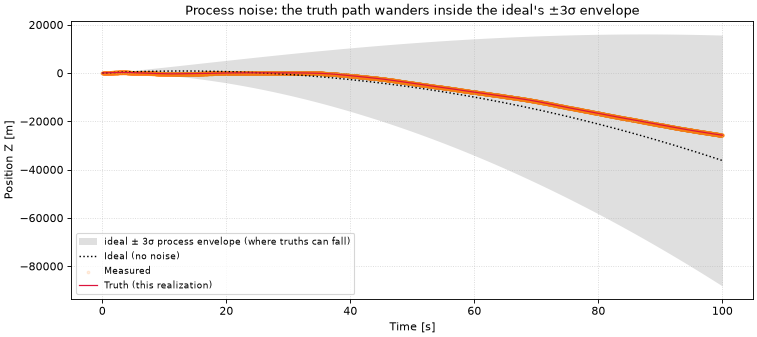

max |truth − ideal| position deviation = 10,503 m (28% of the ideal's range)


In [3]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
import numpy as np

# Process-noise envelope around the IDEAL: propagate P from 0 with the model's F and Q.
F = np.asarray(bulletbill.F(np.zeros((bulletbill.n, 1))))
Q = np.asarray(bulletbill.Q(0))
P = np.zeros((bulletbill.n, bulletbill.n))
env = np.empty(len(sample.time))
for k in range(len(env)):
    env[k] = np.sqrt(max(P[0, 0], 0.0))      # position-component std at step k
    P = F @ P @ F.T + Q

t     = sample.time
ideal = np.asarray(bulletbill.ideal(duration=100))[:, 0]
truth  = np.asarray(sample.xk)[:, 0]
meas  = np.asarray(sample.zk)[:, 0]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(t, ideal - 3*env, ideal + 3*env, color="gray", alpha=0.25, lw=0,
                label="ideal ± 3σ process envelope (where truths can fall)")
ax.plot(t, ideal, ":", color="black", lw=1.3, label="Ideal (no noise)")
ax.scatter(t, meas, s=6, alpha=0.12, color="tab:orange", label="Measured")
ax.plot(t, truth, "-", color="crimson", lw=1.1, label="Truth (this realization)")
ax.set_title("Process noise: the truth path wanders inside the ideal's ±3σ envelope")
ax.set_xlabel("Time [s]"); ax.set_ylabel("Position Z [m]")
ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5); plt.show()

dev = np.abs(truth - ideal)
print(f"max |truth − ideal| position deviation = {dev.max():,.0f} m "
      f"({100*dev.max()/(ideal.max()-ideal.min()):.0f}% of the ideal's range)")

### Interactive Dashboard with Four Panels

A single time slider drives **all four panels at once**: position, speed, acceleration, and the measurement-error histogram. The histogram shows the error distribution growing toward its Gaussian shape.

This dashboard uses the unified `plot(interactive=True, …)` entry point. To build it:
- Pass a list of `component`s. Each one fills one panel.
- Pass `error=True` to add the histogram panel.
- Pass `sample=` to overlay truth and measurements. The plot uses the standard **Measured / Ideal / True / Smoothed** colors.


In [4]:
# The model's interactive signature figure: one joint slider, four pads
# (position / speed / acceleration + measurement-error histogram).
# Reuses `record` / `sample` from the cell above (run it first).
# sigma=3 shades the ±3σ uncertainty band √Pkk from the filter covariance:
# wide early (large P0), it shrinks as measurements accumulate.
bulletbill.plot(record, sample=sample, interactive=True, sigma=3)

### Interpreting the Plots

- **Position** — the smoothed estimate tracks the truth closely, even through noisy measurements. It uses both past and future data.
- **Speed** — the sensor never measures speed directly. The filter reconstructs it from the position history. The RTS smoother removes the startup transient.
- **Acceleration** — the model holds this state **constant** ($\ddot{z}=-9.81$ m/s²). The truth never drifts, because $Q$ has no acceleration term. Position alone only weakly reveals acceleration, so the *forward* filter's estimate is noisy. The RTS smoother recovers a clean, near-constant value. ($q$ drives drift in position and velocity, not in acceleration.)
- **Error histogram** — the residuals should be close to zero-mean and Gaussian. Large tails point to model mismatch or an under-estimated $R$.

> **Try it:** double `measurement_uncertainty` to 64 (σ_z = 64 m). Watch the filter uncertainty widen, while the smoother still recovers a good estimate.


### Is the Filter Honest? Consistency Diagnostics

A good estimate is not enough. The filter must also report **trustworthy uncertainty**. A filter is **consistent** when the errors it makes match the covariance it claims to have.

`model.diagnostics(sample)` draws the standard, model-agnostic dashboard from the last `filter()` run:

- **Innovation (measurement residual)** $\nu = z - H\hat\psi^-$ — shaded with a $\pm 3\sigma$ band from its own predicted spread, $S = HP^-H^\top + R$. It should look like zero-mean noise, mostly inside the band.
- **Kalman gain** over time, on a log or symlog scale — shows how strongly each measurement corrects the state. It settles to a steady value.
- **Normalized Innovation Squared (NIS)** $\nu^\top S^{-1}\nu$ — its mean should be close to $m$ (here $m=1$). NIS needs **no truth data**, so it also works on real data.
- **Normalized Estimation Error Squared (NEES)** $(\psi-\hat\psi)^\top P^{-1}(\psi-\hat\psi)$ — its mean should be close to $n$ (here $n=3$). NEES needs the true state. A value far above $n$ means the filter is over-confident. A value far below $n$ means the filter is over-cautious.

The individual numbers are also available directly: `model.innovations()`, `model.gains()`, `model.nis()`, and `model.nees(truth)`.


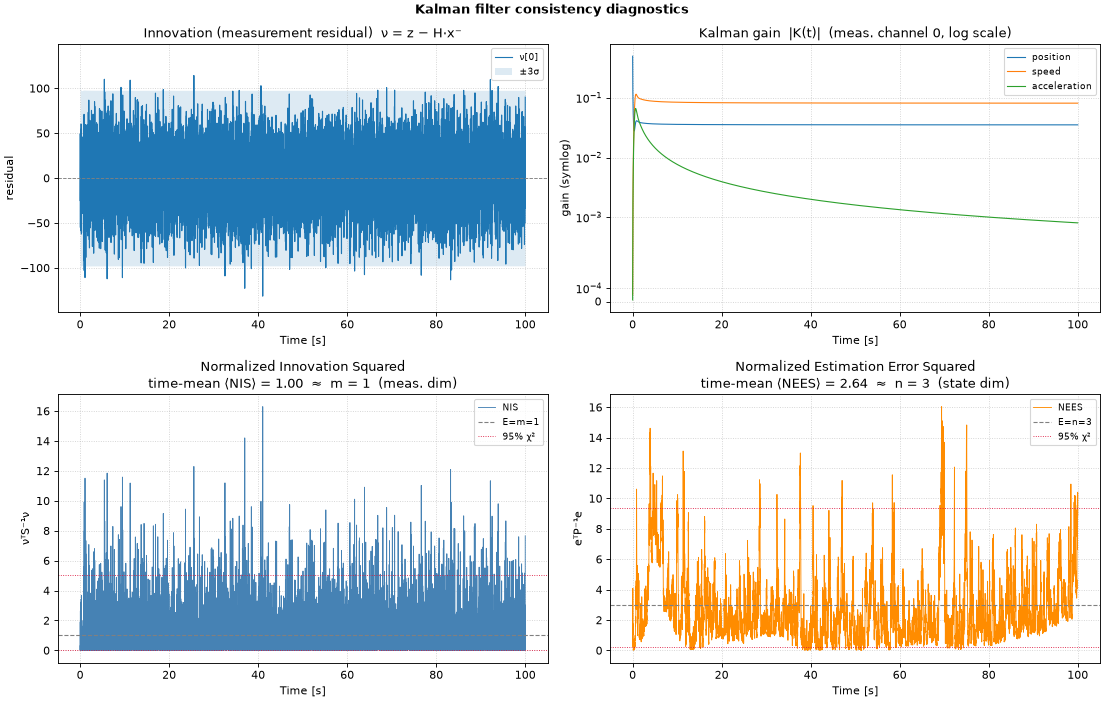

Normalized Innovation Squared,        mean = 1.00   (ideal ≈ m = 1)
Normalized Estimation Error Squared,  mean = 2.64   (ideal ≈ n = 3)


In [5]:
# Consistency dashboard for the linear filter run above (reuses `bulletbill` / `sample`).
import matplotlib.pyplot as plt

bulletbill.diagnostics(sample=sample)     # innovation + gain + NIS + NEES (NEES needs the truth)
plt.show()

print(f"Normalized Innovation Squared,        mean = {bulletbill.nis().mean():.2f}   (ideal ≈ m = {bulletbill.m})")
print(f"Normalized Estimation Error Squared,  mean = {bulletbill.nees(sample.xk).mean():.2f}   (ideal ≈ n = {bulletbill.n})")

### Estimating the Apex and the Impact Time

Two quantities often matter for a track: the **apex** (the maximum height) and the **impact time** (when the body crosses ground level, z = 0).

`BallisticLinearModel` provides closed-form estimators for both. Each takes a `[z, ż, z̈]` state. Each assumes the model's own constant-acceleration motion from that instant:

- `apex(state, cov)` returns the time to peak, `t* = −ż/z̈`, and the peak height, `z* = z − ż²/(2 z̈)`.
- `impact_time(state, cov, level=0)` returns the future *descending* root of `½ z̈ t² + ż t + (z − level) = 0`.

Pass the matching covariance (`Pk[k]`). Each estimator then also returns a **1-σ uncertainty**, using first-order propagation, $\sigma^2 = J^\top P J$.

We evaluate both estimators on the **smoothed** track, at the relevant instant. For the apex, this is the peak sample. For the impact, this is the sample just before the ground crossing. Strong process noise makes the *overall* path far from a clean parabola, but the local constant-acceleration assumption still holds well at these single instants.


In [6]:
# Smoothed track gives the best state estimates for reading off apex / impact.
smoothed = bulletbill.smooth()
x_smooth = np.asarray(smoothed.xk); P_smooth = np.asarray(smoothed.Pk); t_smooth = np.asarray(smoothed.time)
z_true = np.asarray(sample.xk)[:, 0]

# --- Apex: estimator at the instant of greatest estimated height -------------
apex_idx = int(np.argmax(x_smooth[:, 0]))
apex     = bulletbill.apex(x_smooth[apex_idx], P_smooth[apex_idx])
print(f"Apex (max height) : {apex.height:8,.0f} ± {apex.height_std:5,.0f} m   "
      f"at t = {t_smooth[apex_idx] + apex.time:5.2f} s     "
      f"(truth {z_true.max():,.0f} m at {t_smooth[int(np.argmax(z_true))]:.2f} s)")

# --- Impact: estimator at the sample just before the first descending z=0 crossing
impact_idx       = np.where(np.diff(np.sign(x_smooth[:, 0])) < 0)[0][0]
impact           = bulletbill.impact_time(x_smooth[impact_idx], P_smooth[impact_idx], level=0.0)
true_impact_idx  = np.where(np.diff(np.sign(z_true)) < 0)[0][0]
true_impact_time = (t_smooth[true_impact_idx]
                     - z_true[true_impact_idx] * (t_smooth[true_impact_idx + 1] - t_smooth[true_impact_idx])
                       / (z_true[true_impact_idx + 1] - z_true[true_impact_idx]))
print(f"Impact (z = 0)    : t = {t_smooth[impact_idx] + impact.time:5.2f} ± {impact.time_std:.2f} s   "
      f"impact speed {impact.speed:6,.0f} m/s   (truth t = {true_impact_time:.2f} s)")


Apex (max height) :      248 ±     3 m   at t =  3.36 s     (truth 244 m at 3.36 s)
Impact (z = 0)    : t =  6.23 ± 0.03 s   impact speed    -96 m/s   (truth t = 6.19 s)


## Step 2 — Ensemble Analysis with `KalmanRecordCollection`

A single filter run shows only **one** random draw of the measurement noise. That single run might look great by chance, or unlucky by chance. To judge a filter honestly, look at its **behaviour over many runs**.

**Key terms**
- **Monte Carlo ensemble** — repeat the experiment $N$ times with independent noise, then combine the results.
- **Filter consistency** — a filter is *consistent* when its reported uncertainty matches its actual errors. The truth should fall inside the filter's predicted $\pm2\sigma$ band about **95%** of the time. An over-confident filter lets errors leak outside the band, which is dangerous. An over-conservative filter wastes information.
- **Empirical vs. predicted covariance** — the spread of the ensemble (empirical) should match the covariance $P$ the filter computes (predicted).

`KalmanRecordCollection` runs and overlays the trials. It lets you see the error cloud, the $\pm2\sigma$ envelope, and compare different parameter settings side by side.

*What to look for:* the ensemble spread sits inside the predicted band. This confirms that the filter's self-reported confidence is trustworthy.


Run 1/2: 0.028066s
Run 2/2: 0.056800s
KalmanRecordCollection with 2 records: 
  0: KalmanRecord(N=2048, n=3, m=1, flavor=smoothed, model=Ballistic State Model)
  1: KalmanRecord(N=2048, n=3, m=1, flavor=smoothed, model=Ballistic State Model)


(<Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>,
 <Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>)

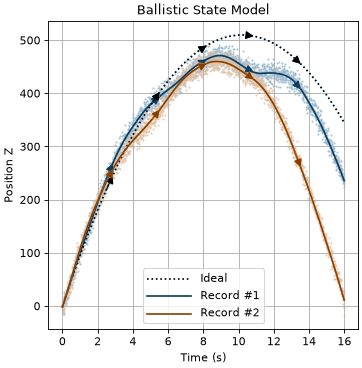

In [7]:
from kalman.apps.ballistics import BallisticLinearModel
from kalman.framework.io.collection import KalmanRecordCollection

bulletbill = BallisticLinearModel("Z", sample_rate=128,
                                  measurement_uncertainty=10,    # σ_z  [m]    sensor noise std (R = σ_z²)
                                  process_uncertainty=10.0)      # σ_a  [m/s²] accel-noise std (Q = σ_a²·block)
bulletbill.initial_state([0, 100, -GRAVITY])

chrono.restart()

N = 2
samples, records = [], []
for i in range(N):
    samples.append(bulletbill.sample(16))
    records.append(bulletbill.filter(samples[-1], smooth=True, reset=True))
    if i % 4 == 0 or i == N - 1:
        print(chrono.lap(f"Run {i+1}/{N}"), end="\r" if i < N - 1 else "\n")

collection = KalmanRecordCollection(records)
collection.print()

# Overlay all runs on a single plot
collection.plot(samples=samples, component=bulletbill.states.POSITION)

### Interpreting the Ensemble Plot

Each line is an independent run. The spread between lines reflects the effect of measurement noise on the filtered trajectory.

A well-calibrated filter shows scatter consistent with the predicted covariance $P_k$. The scatter should not be systematically tighter or wider than that.

- If the scatter is wider than the $\pm 2\sigma$ bands, the sensor noise $R$ is under-estimated.
- If all runs look nearly identical, $R$ may be over-estimated. The filter then trusts the model too much.


## Step 3 — 3D Composite Linear Kalman Filter (Independent Axes)

Real motion happens in three dimensions. The simplest 3D filter treats the X, Y, and Z axes as **independent** 1D trackers running in parallel. This works whenever nothing couples the axes together.

**Key terms**
- **Composite model** — `CompositeKalmanModel` stacks several sub-models into one larger model. It builds the combined **block-diagonal** $F$, $H$, $Q$, and $R$ matrices automatically.
- **Block-diagonal covariance** — the off-diagonal blocks are zero. This means the axes share no information; each axis evolves entirely on its own.
- **Axis-major layout** — the state groups all components of one axis together: $\psi = (x,\,v_x,\,a_x,\;y,\,v_y,\,a_y,\;z,\,v_z,\,a_z)$.

This decoupling is *exact* only under two conditions. First, each axis must have constant acceleration. Second, there must be **no coupling force** between axes, such as central gravity or speed-dependent drag (for example, in short-range, high-speed flight). Step 4 shows what breaks when this assumption fails.

The `dim` plot argument selects the spatial axis: 0 for X, 1 for Y, 2 for Z.


KalmanRecord:
    Summary:
        Attached Model....................................: Composite Kalman Model (v1.0)
        Description.......................................: float64
        Samples...........................................: 2048 data points
        Sample Rate.......................................: 128 Hz
        State Dimension (n)...............................: 9D
        Observation Dimension (m).........................: 3D
        Flavor............................................: posterior
        Start Time........................................: 0s
        Duration..........................................: 16s
    Dimensions & Data Quality:
        Time (s) .........................................: [0s .. 16s[
        Measurements (zk) ................................: 2048x(3)
        State Vector (xk) ................................: 2048x(9)
        State Covariance (Pk) ............................: 2048x(9x9)

    State Vector Averages (per dime

Chrono summary:
    #   label                                t          ΔT
  ───   ──────────────────────────   ─────────   ─────────
    1.  Model initialized               0.7 ms      0.7 ms
    2.  Sampling completed            185.8 ms    185.1 ms
    3.  Filtering completed           549.9 ms    364.1 ms
    4.  Position plots completed       1.156 s    606.6 ms
    5.  Speed plots completed          1.728 s    571.8 ms
    6.  Correlation plot completed     1.919 s    191.1 ms
  ───   ──────────────────────────   ─────────   ─────────
        total                          1.919 s


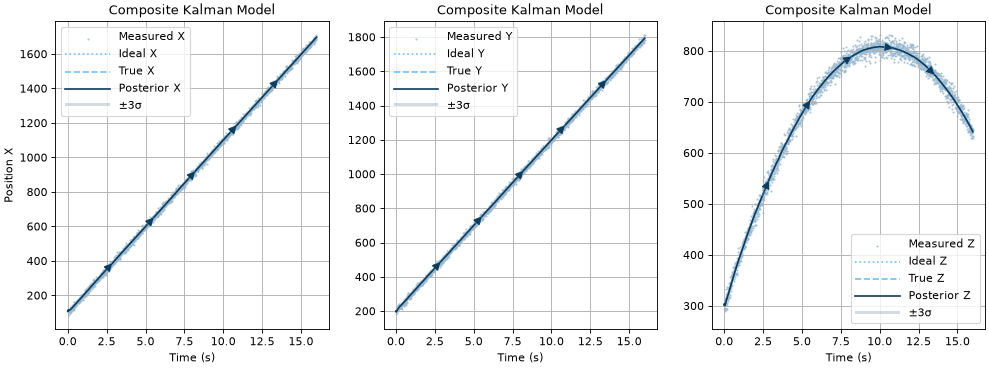

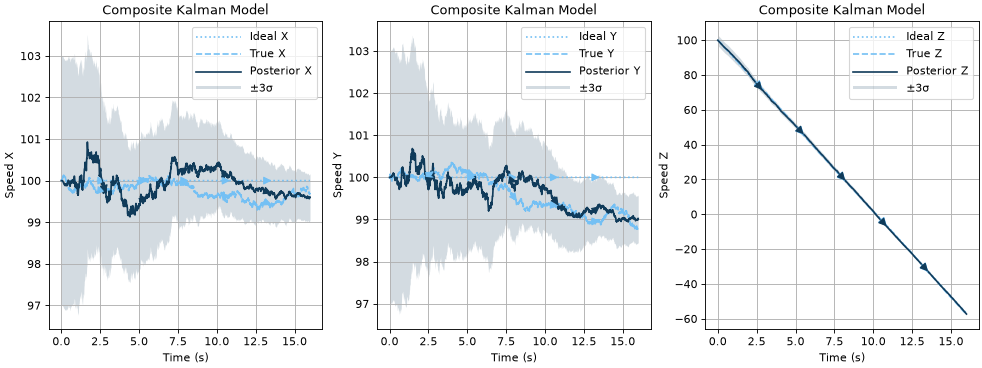

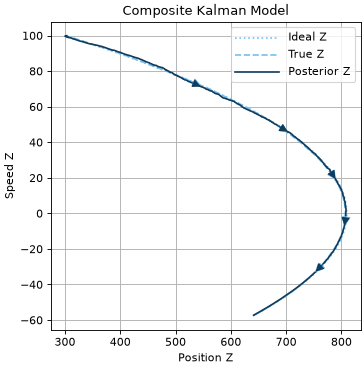

In [8]:
chrono.restart()

from kalman.apps.ballistics import BallisticLinearModel
from kalman.framework.models.composite import CompositeKalmanModel

# Per axis the two noises are standard deviations:
#   measurement_uncertainty = σ_z [m]    position-sensor noise std (R = σ_z²)
#   process_uncertainty     = σ_a [m/s²] accel-noise std          (Q = σ_a²·block)
bulletbill = CompositeKalmanModel(
    BallisticLinearModel("X", sample_rate=128, measurement_uncertainty=10, process_uncertainty=0.2, random_seed=42),
    BallisticLinearModel("Y", sample_rate=128, measurement_uncertainty=10, process_uncertainty=0.2, random_seed=43),
    BallisticLinearModel("Z", sample_rate=128, measurement_uncertainty=10, process_uncertainty=0.2, random_seed=44)
)
bulletbill.initial_state([
    [100, 100,     0],   # X: [px, vx, ax]
    [200, 100,     0],   # Y: [py, vy, ay]
    [300, 100, -GRAVITY]    # Z: [pz, vz, az]
])
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=False, reset=True)
record.print()
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
from kalman.apps.ballistics import BallisticObservable

canvas = get_canvas(3, 1)
# sigma=3 shades the ±3σ uncertainty band (√Pkk) on each panel
record.plot(sample=sample, component="position", dim=0, fig=canvas[0], sigma=3)
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey=True, sigma=3)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey=True, sigma=3)
chrono.lap("Position plots completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0], sigma=3)
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1], sigma=3)
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2], sigma=3)
chrono.lap("Speed plots completed")

# Phase plot: position (Z) vs speed (Z)
record.plot(sample=sample, component=["position", "speed"], dim=[2, 2])
chrono.lap("Correlation plot completed")

chrono.summary()

### Key Observations

- Each axis is filtered independently, using its own `random_seed`. Errors in X do not affect Y or Z.
- The shaded **±3σ band** ($\sqrt{P_{kk}}$) is the filter's own reported uncertainty. The X and Y *speed* estimates wander by about ±1 m/s around the constant value of 100 m/s. This wander is **genuine process noise**: the random-walk velocity injected by `process_uncertainty`, estimated causally from position alone. It stays inside the ±3σ band, so the filter is honest. The Z speed spans 100 to −57 m/s; its much larger axis scale simply hides the same small wander.
- The Z phase plot (position vs. speed along the same axis) traces the parabolic arc. Speed decreases as the projectile rises, crosses zero at the apex, then becomes negative on descent. This forms a clear ellipse-like curve when the filter tracks well.
- `smooth=False` here shows only the **causal** (realtime-capable) filter, without the backward pass.


## Step 4 — 3D Nonlinear Extended Kalman Filter

### Why a Linear Filter Is No Longer Enough

The independent-axes model in Step 3 assumes nothing couples X, Y, and Z. Two real effects break that assumption:

1. **Central gravity** — $\mathbf a_\text{grav}=-GM\,\mathbf p/\lVert\mathbf p\rVert^{3}$ points toward Earth's centre. It depends **nonlinearly on all three** position components. The constant vector $[0,0,-g]$ is only a flat-Earth approximation.
2. **Aerodynamic drag** — $\mathbf a_\text{drag}=-(c_d/m)\lVert\mathbf v\rVert\mathbf v$ couples the velocity components through the **speed** term $\lVert\mathbf v\rVert$.

**Key terms**
- **Extended Kalman Filter (EKF)** — the standard tool for nonlinear systems. It propagates the *mean* with the **true nonlinear dynamics** $f(\mathbf x)$, but propagates the *covariance* with a local linearisation.
- **Jacobian** $F=\partial f/\partial\mathbf x$ — the matrix of partial derivatives that linearises $f$ around the current estimate. The framework computes it numerically here.

The state is axis-major and 9-dimensional: `x = [px,vx,ax, py,vy,ay, pz,vz,az]`. The measurement is position only, so $H$ extracts $[p_x,p_y,p_z]$.

*What to look for:* the EKF follows a curved, axis-coupled trajectory. The independent-axes linear model from Step 3 cannot represent this curve.


BallisticModel(KalmanModel) @ fs=64Hz
    Ballistic Extended Model (v1.0)
        Nonlinear 3D ballistic model with gravity, drag,
        and thrust.
    Dimensions Summary:
        State Vector....................................: 9 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 3 dims (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims
    Metadata Entries:
        G      = 6.674e-11 (float)
        M      = 5.972e+24 (float)
        c_drag = 0 (int)
        g      = 9.81 (float)
        m      = 1.0 (float)



Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Model initialized        0.8 ms      0.8 ms
    2.  Sampling completed      1.175 s     1.174 s
    3.  Filtering completed     2.455 s     1.280 s
    4.  State grid plotted     12.629 s    10.174 s
    5.  3D + error plotted     14.862 s     2.233 s
  ───   ───────────────────   ─────────   ─────────
        total                  14.862 s


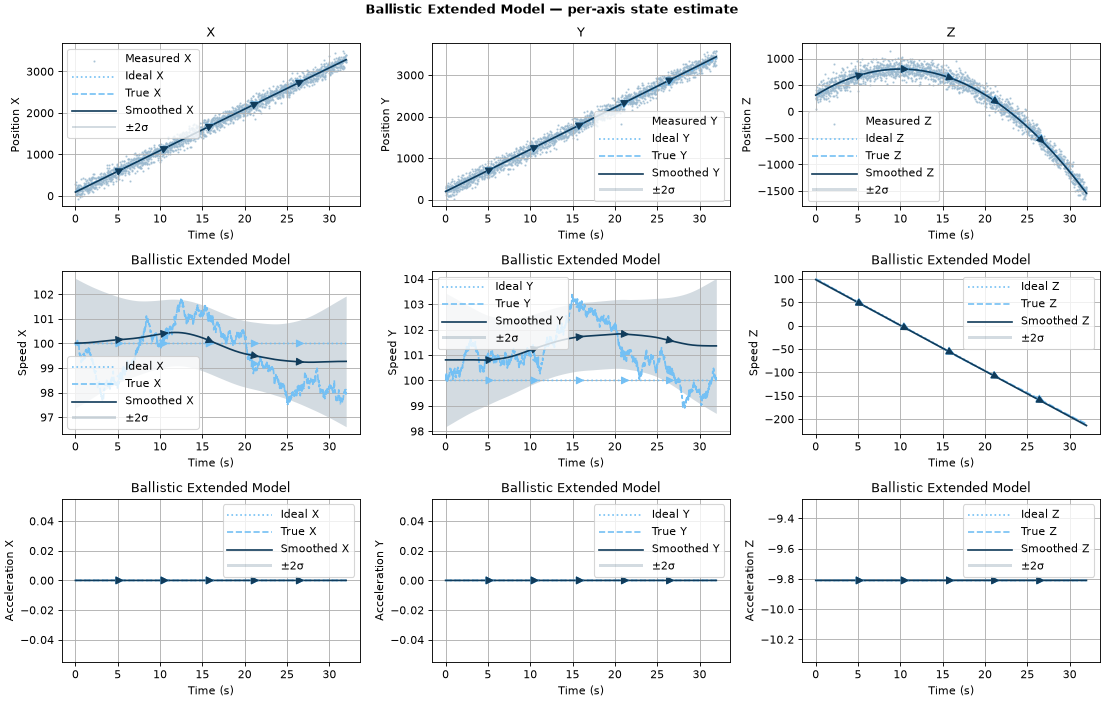

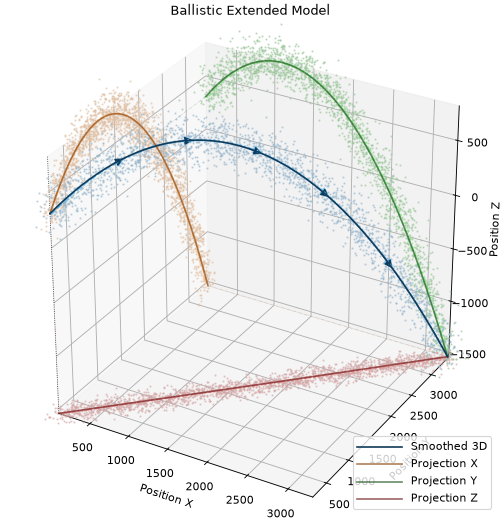

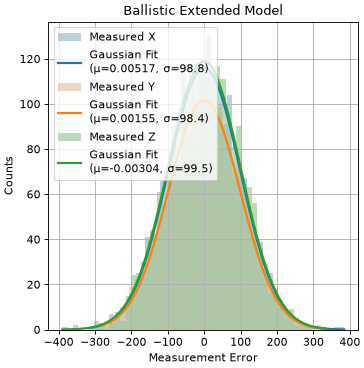

In [9]:
chrono.restart()

from kalman.apps.ballistics import BallisticModel

# Same std conventions as the linear model, now in 3-D:
#   measurement_uncertainty = σ_z [m]    position-sensor noise std → R = σ_z²·I₃
#   process_uncertainty     = σ_a [m/s²] accel-noise std          → Q = σ_a²·block, per axis
bulletbill = BallisticModel("XYZ", order=3, fs=64,
                            measurement_uncertainty=100,   # σ_z  [m]    sensor noise std
                            process_uncertainty=0.5,       # σ_a  [m/s²] accel-noise std
                            random_seed=42)

# Axis-major initial state: each row = [pos, vel, acc] for one spatial axis
bulletbill.initial_state([
    [100, 100,     0],    # X: [px, vx, ax]
    [200, 100,     0],    # Y: [py, vy, ay]
    [300, 100, -GRAVITY],    # Z: [pz, vz, az]
])
bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(32)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=True, reset=True)
chrono.lap("Filtering completed")

# Signature figure: per-axis (position / speed / acceleration) state grid.
# sigma=2 shades the ±2σ band √Pkk from the filter covariance on every panel.
bulletbill.plot(record, sample=sample, sigma=2)
chrono.lap("State grid plotted")

# 3D trajectory + measurement-error histogram (record-level one-liners).
record.plot(sample=sample, component="position", view="3d")
record.plot_error(sample=sample)
chrono.lap("3D + error plotted")

chrono.summary()

### EKF vs. Linear Model: What Changes?

- **Velocity estimate** — the EKF couples the drag effect across axes. When the projectile slows in Z due to drag, this effect propagates to X and Y through the shared $\|\mathbf{v}\|$ term.
- **Acceleration estimate** — the recovered acceleration converges toward the true gravitational and drag acceleration, rather than toward a fitted linear trend.
- **Covariance** — the EKF propagates covariance through the Jacobian. This correctly accounts for the local nonlinearity of the dynamics at each time step.
- **3D trajectory** — shows the full parabolic arc. This view is useful for visualising sensor coverage and geometric constraints.


## Step 5 — A Real Projectile: Mass, Air Friction, and a Mortar Shell

The EKF dynamics already carry the projectile's **mass**, `m` [kg]. Mass enters exactly where Newton's second law puts it: in the **acceleration**, not the force:

$$\dot{\mathbf v}=\underbrace{\mathbf g}_{\text{gravity (mass-free)}}\;-\;\frac{c_d}{m}\,\lVert\mathbf v\rVert\,\mathbf v\;+\;\frac{\mathbf u}{m}.$$

- **Gravity** does not depend on mass (Galileo's result): a heavy shell and a light shell fall identically *in vacuum*.
- **Air friction (drag)** and **thrust** are *forces*, so their acceleration scales as $1/m$. A heavier shell **resists drag better**. For a given drag coefficient $c_d$, it decelerates less and flies farther. The range is really set by the **ballistic coefficient**, $\propto m/(C_d A)$.

**Air friction: in $f$, or in $Q$?** Both, but each has a different job:

- The **mean** drag is *deterministic*. It is the term $-\frac{c_d}{m}\lVert\mathbf v\rVert\mathbf v$ inside $f$, and it is already there.
- The **uncertainty** in that drag is *stochastic*. It comes from an imperfect $C_d$, air-density and wind fluctuations, and an un-modelled transonic rise. This belongs in the **process noise** $Q$. We size it from the drag itself: $\sigma_a\approx\varepsilon\,\frac{c_d}{m}v^2$, for a fractional drag error $\varepsilon$.

Putting the drag *force* into $Q$ would be wrong: $Q$ holds what we **do not** model, not what we already model.

> A constant $Q$ sized from the muzzle speed is a conservative upper bound. A better refinement is a **state-dependent** $Q(\mathbf v)\propto v^4$. This is largest at the muzzle and vanishes at the apex. We enable it just below with `drag_uncertainty=ε`.

Below, we track a realistic **81 mm mortar** shell (muzzle velocity v₀ = 250 m/s, mass 4.2 kg), fired at 60°. Its $Q$ is sized from a ±15 % drag uncertainty. We then compare the *same* body at three masses, landing short or long.

| Mortar | Calibre | Muzzle velocity | Shell mass |
|---|---|---|---|
| Light | 60 mm | 70–200 m/s | ~1.3 kg |
| Medium | 81/82 mm | 100–300 m/s | ~4.2 kg |
| Heavy | 120 mm | 150–350 m/s | ~13 kg |


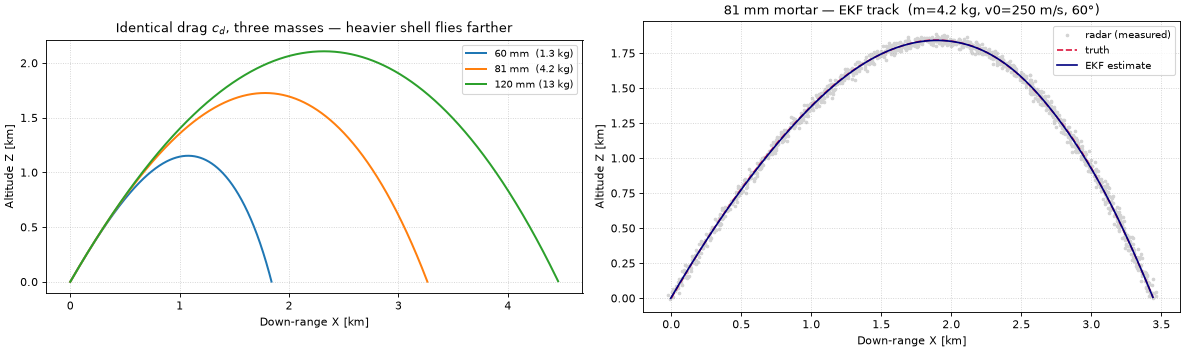

Air-friction process noise:  sigma_a = eps*(c_d/m)*v0^2 = 1.34 m/s^2   (eps = 15%)
Impact range & apex at fixed drag c_d = 6.0e-04 kg/m (same launch, varying mass):
  60 mm  (1.3 kg)  range =  1.84 km   apex =  1.15 km
  81 mm  (4.2 kg)  range =  3.26 km   apex =  1.73 km
  120 mm (13 kg)   range =  4.46 km   apex =  2.11 km
EKF position RMS (81 mm) = 2.1 m
Chrono summary:
    #   label                                   t          ΔT
  ───   ─────────────────────────────   ─────────   ─────────
    1.  81 mm mortar tracked with EKF     1.668 s     1.668 s
    2.  mass sweep done                   4.071 s     2.403 s
  ───   ─────────────────────────────   ─────────   ─────────
        total                             4.229 s


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
import kalman.runtime.chrono as chrono

chrono.restart()

# --- 81 mm mortar shell (the EKF model already carries the mass `m`) --------
V0     = 250.0           # muzzle velocity [m/s]   (81 mm mortar: 100–300 m/s)
ELEV   = np.radians(60)  # launch elevation        (mortars are high-angle weapons)
MASS   = 4.2             # shell mass [kg]
C_DRAG = 6.0e-4          # aerodynamic drag c_d [kg/m] ≈ ½·ρ·C_D·A for an 81 mm body
FS     = 32              # tracking-radar rate [Hz]

# Fire in the X–Z plane: vx = V0 cosθ (down-range), vz = V0 sinθ (up)
def mortar_init(v0, elev):
    return [[0.0, v0*np.cos(elev),  0.0],   # X: [px, vx, ax]
            [0.0, 0.0,              0.0],    # Y: [py, vy, ay]
            [0.0, v0*np.sin(elev), -GRAVITY]]  # Z: [pz, vz, az]  (climbing at launch)

def impact_range(x, z):                      # X where the shell crosses z = 0 (linear interp)
    below = np.where(z < 0)[0]
    if len(below) == 0 or below[0] == 0: return x[-1]
    k = below[0]; z0, z1 = z[k-1], z[k]
    return x[k-1] + (x[k]-x[k-1]) * (z0/(z0-z1))

T_FLIGHT = 1.05 * 2.0*V0*np.sin(ELEV)/GRAVITY   # ≈ vacuum flight time (+5%); drag lands it sooner

# Air-friction UNCERTAINTY → process noise Q.  The MEAN drag is the deterministic
# a_drag = (c_d/m)|v|v already inside f(); Q only carries what we DON'T know about
# it (imperfect Cd, air-density & wind fluctuations). Size sigma_a from a fractional
# drag error at muzzle speed: sigma_a ≈ eps·(c_d/m)·v0^2  (largest fast, ~0 at apex).
EPS_DRAG = 0.15                              # ±15% unknown in the drag
SIGMA_A  = EPS_DRAG * (C_DRAG/MASS) * V0**2  # process-noise accel std [m/s²]

# --- Track the 81 mm shell with the EKF ------------------------------------
mortar = BallisticModel("XYZ", order=3, fs=FS,
                        m=MASS,                       # ← shell mass [kg]; with drag on, it shapes the arc
                        c_drag=C_DRAG,                # mean air friction → deterministic a_drag in f()
                        g=GRAVITY,                       # flat-Earth gravity (mass-free)
                        measurement_uncertainty=20,   # σ_z [m]    radar position noise
                        process_uncertainty=SIGMA_A,  # σ_a [m/s²] air-friction uncertainty → Q
                        random_seed=7)
mortar.initial_state(mortar_init(V0, ELEV))
sample = mortar.sample(T_FLIGHT)
record = mortar.filter(sample.zk, smooth=True, reset=True)
chrono.lap("81 mm mortar tracked with EKF")

# --- Why the model needs mass: same body & drag, three shell masses ---------
# Hold the drag c_d and launch fixed, vary ONLY the mass (no process noise here —
# we compare the deterministic MEAN arcs): the spread is pure Newton a = F/m.
masses = {"60 mm  (1.3 kg)": 1.3, "81 mm  (4.2 kg)": 4.2, "120 mm (13 kg)": 13.0}
sweep = {}
for lbl, mass in masses.items():
    shot = BallisticModel("XYZ", order=3, fs=FS, m=mass, c_drag=C_DRAG, g=GRAVITY,
                          process_uncertainty=0.0, measurement_uncertainty=1.0, random_seed=0)
    shot.initial_state(mortar_init(V0, ELEV))
    traj = shot.sample(T_FLIGHT)
    sweep[lbl] = (traj.xk[:, 0], traj.xk[:, 6])     # (down-range X, altitude Z)
chrono.lap("mass sweep done")

# --- Plots ------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for lbl, (x, z) in sweep.items():             # left: mass sweep (clipped at ground)
    k = z >= 0
    ax[0].plot(x[k]/1000, z[k]/1000, lw=1.8, label=lbl)
ax[0].set_title("Identical drag $c_d$, three masses — heavier shell flies farther")
ax[0].set_xlabel("Down-range X [km]"); ax[0].set_ylabel("Altitude Z [km]")
ax[0].legend(fontsize=9); ax[0].grid(True, ls=":", alpha=0.6); ax[0].set_aspect("equal", "box")

mk = sample.xk[:, 6] >= 0                      # right: EKF track of the 81 mm shell
ax[1].scatter(sample.zk[mk, 0]/1000, sample.zk[mk, 2]/1000, s=5, color="lightgray", zorder=0, label="radar (measured)")
ax[1].plot(sample.xk[mk, 0]/1000, sample.xk[mk, 6]/1000, '--', color="crimson", lw=1.5, label="truth")
ax[1].plot(record.xk[mk, 0]/1000, record.xk[mk, 6]/1000, '-',  color="navy",    lw=1.5, label="EKF estimate")
ax[1].set_title(f"81 mm mortar — EKF track  (m={MASS} kg, v0={V0:.0f} m/s, 60°)")
ax[1].set_xlabel("Down-range X [km]"); ax[1].set_ylabel("Altitude Z [km]")
ax[1].legend(fontsize=9); ax[1].grid(True, ls=":", alpha=0.6); ax[1].set_aspect("equal", "box")

plt.tight_layout(); plt.show()

print(f"Air-friction process noise:  sigma_a = eps*(c_d/m)*v0^2 = {SIGMA_A:.2f} m/s^2   (eps = {EPS_DRAG:.0%})")
print(f"Impact range & apex at fixed drag c_d = {C_DRAG:.1e} kg/m (same launch, varying mass):")
for lbl, (x, z) in sweep.items():
    print(f"  {lbl:16s} range = {impact_range(x, z)/1000:5.2f} km   apex = {z.max()/1000:5.2f} km")
print(f"EKF position RMS (81 mm) = {np.sqrt(np.mean((record.xk[:,[0,6]]-sample.xk[:,[0,6]])**2)):.1f} m")
chrono.summary()

### State-Dependent Q: Air-Friction Uncertainty That Follows the Speed

Now we enable the speed-dependent process noise. Passing `drag_uncertainty=ε` makes the EKF's $Q$ grow as $Q(\mathbf v)\propto v^4$ (in variance).

This means the filter is least certain exactly when the shell is **fast**, since drag is hardest to know at high speed. The uncertainty relaxes back to the constant base value near the **apex**, where the shell is slow.

The framework forwards the predicted state to `Q` to make this possible. The constant-acceleration `BallisticLinearModel` has no velocity-dependent dynamics, so its `Q` stays deliberately **constant**.


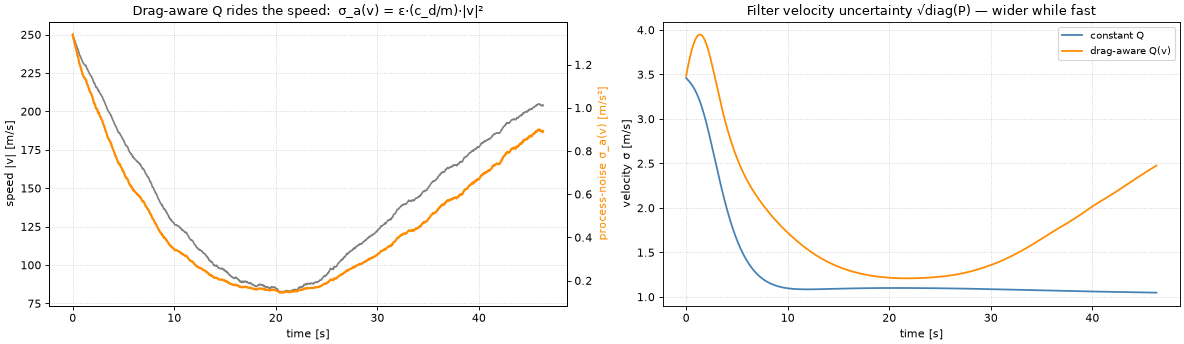

σ_a(v):  0.14 m/s² (apex, slow)  ->  1.34 m/s² (muzzle, fast)
velocity σ at launch:  constant Q = 3.33   drag-aware = 3.80  m/s
velocity σ near apex:  constant Q = 1.10   drag-aware = 1.21  m/s


In [11]:
# ---------------------------------------------------------------------------
# State-dependent Q — the FILTER's air-friction uncertainty rides the speed.
# Reuses V0/ELEV/MASS/C_DRAG/FS/EPS_DRAG/mortar_init/sample from the cell above.
# Two EKFs on the SAME radar track:  constant Q   vs   Q(v)=ε·(c_d/m)|v|² (drag-aware).
# ---------------------------------------------------------------------------
ekf_const = BallisticModel("XYZ", order=3, fs=FS, m=MASS, c_drag=C_DRAG, g=GRAVITY,
                           measurement_uncertainty=20, process_uncertainty=0.3)
ekf_drag  = BallisticModel("XYZ", order=3, fs=FS, m=MASS, c_drag=C_DRAG, g=GRAVITY,
                           measurement_uncertainty=20, process_uncertainty=0.3,
                           drag_uncertainty=EPS_DRAG)        # ← Q now grows with speed (v⁴ in variance)
ekf_const.initial_state(mortar_init(V0, ELEV)); rec_const = ekf_const.filter(sample.zk, smooth=False, reset=True)
ekf_drag .initial_state(mortar_init(V0, ELEV)); rec_drag  = ekf_drag .filter(sample.zk, smooth=False, reset=True)

t    = sample.time
speed  = np.linalg.norm(sample.xk[:, [1, 4, 7]], axis=1)                  # true speed |v(t)|
sigma_a_drag   = EPS_DRAG * (C_DRAG/MASS) * speed**2                                # σ_a(v) the drag-EKF assumes
velocity_sigma = lambda rec: np.sqrt(np.clip(rec.Pk[:, [1, 4, 7], [1, 4, 7]].sum(1), 0.0, None))  # total velocity σ

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].plot(t, speed, color="gray", lw=1.5)
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("speed |v| [m/s]"); ax[0].grid(True, ls=":", alpha=0.6)
ax0b = ax[0].twinx()
ax0b.plot(t, sigma_a_drag, color="darkorange", lw=2.0)
ax0b.set_ylabel("process-noise σ_a(v) [m/s²]", color="darkorange")
ax[0].set_title("Drag-aware Q rides the speed:  σ_a(v) = ε·(c_d/m)·|v|²")

ax[1].plot(t, velocity_sigma(rec_const), color="steelblue",  lw=1.6, label="constant Q")
ax[1].plot(t, velocity_sigma(rec_drag),  color="darkorange", lw=1.6, label="drag-aware Q(v)")
ax[1].set_title("Filter velocity uncertainty √diag(P) — wider while fast")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("velocity σ [m/s]")
ax[1].legend(fontsize=9); ax[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

print(f"σ_a(v):  {sigma_a_drag.min():.2f} m/s² (apex, slow)  ->  {sigma_a_drag.max():.2f} m/s² (muzzle, fast)")
print(f"velocity σ at launch:  constant Q = {velocity_sigma(rec_const)[:50].mean():.2f}   drag-aware = {velocity_sigma(rec_drag)[:50].mean():.2f}  m/s")
print(f"velocity σ near apex:  constant Q = {velocity_sigma(rec_const)[len(t)//2-25:len(t)//2+25].mean():.2f}   drag-aware = {velocity_sigma(rec_drag)[len(t)//2-25:len(t)//2+25].mean():.2f}  m/s")

## Possible Improvements and Extensions

### 1. Add a Doppler Radar Sensor (Multi-Modal EKF)

A Doppler radar measures **radial velocity**, $\dot{r} = \mathbf{v} \cdot \hat{\mathbf{r}}$. This is a nonlinear function of the state.

Adding this as a second measurement channel improves velocity observability. It does this without needing a second position sensor.

Implementation: subclass `BallisticModel`. Override `h()` to return `[px, py, pz, vrad]`. Update `H` with its Jacobian.

### 2. Estimate the Drag Coefficient as an Augmented State

Make `c_drag` a state variable. Let it evolve as a random walk:
```
ċ_drag = w_drag   (white noise process)
```
Augment the state to `[px,vx,ax, py,vy,ay, pz,vz,az, c_drag]` (10 dimensions).

The EKF then adaptively estimates drag from the deceleration pattern. This is useful when the projectile's aerodynamic properties are uncertain.

### 3. Unscented Kalman Filter (UKF)

The EKF uses a first-order (Jacobian) approximation. This propagates uncertainty through nonlinear dynamics.

The UKF instead uses a set of sigma points. These capture second-order statistics, which gives more accuracy for strongly nonlinear systems, at a modest extra computational cost.

The `kalman` framework provides `KalmanUnscentedFilter` as a drop-in replacement for `KalmanFilter`.

### 4. Multi-Sensor Fusion with NaN Masking

Sensors often update at different rates. For example, a GPS may update at 10 Hz while an IMU updates at 1000 Hz.

Use `NaN` rows in the measurement array to handle this. The filter skips the update step for `NaN` rows and runs a prediction-only step instead. This keeps state continuity between measurements.

See `04_Suspension.ipynb` for a worked multi-rate example.


## Step 6 — Multi-Modal EKF: Position and Doppler Radial Velocity

### Motivation: Observability

A **position-only** sensor makes velocity only *weakly observable*. The filter must infer velocity from the *change* in position between steps. This makes the velocity estimate lag and stay noisy.

A **Doppler radar** removes this weakness. It measures velocity almost directly.

**Key terms**
- **Observability** — how well a quantity can be inferred from the available measurements. A sensor that responds to velocity makes velocity *strongly* observable.
- **Radial velocity** $\dot r=\mathbf v\cdot\hat{\mathbf r}$ — the velocity component *along the line of sight* from the radar. This is exactly what a Doppler shift measures.
- **Multi-modal fusion (sensor fusion)** — combining sensors of different types inside one filter. Here we combine position and velocity.

The Doppler term is **nonlinear**: it mixes position and velocity. This means it needs the EKF. We subclass `BallisticModel`, override `h()` to append $\dot r$, and let the framework compute the Jacobian $H=\partial h/\partial\mathbf x$ numerically:

$$\mathbf z=[p_x,p_y,p_z,\dot r]^\top+\mathbf v,\qquad
R=\mathrm{diag}(r_\text{pos}^2,r_\text{pos}^2,r_\text{pos}^2,r_\text{vel}^2).$$

*What to look for:* the velocity error drops sharply once the Doppler channel is added, compared to position-only tracking.


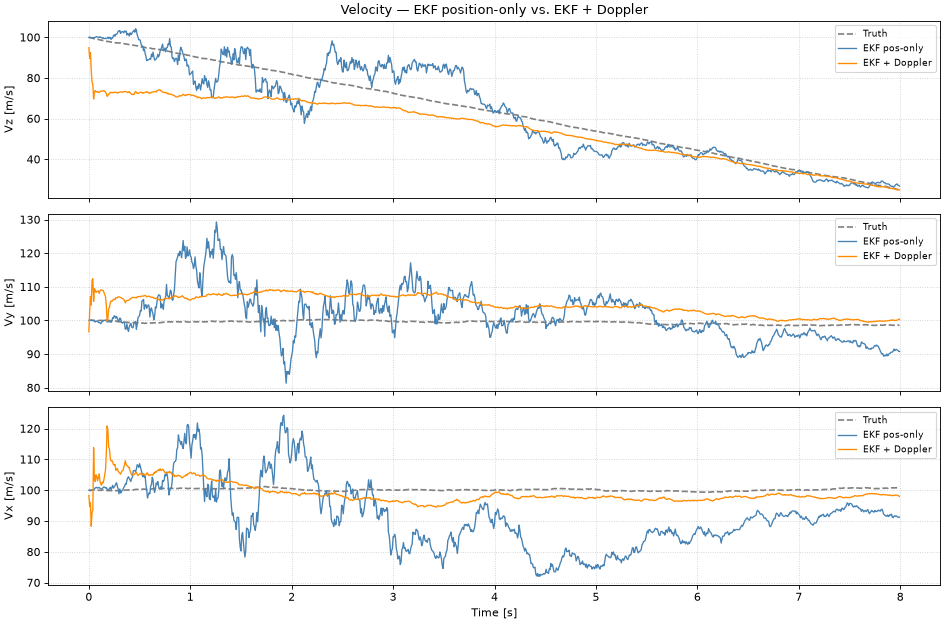

Vx RMS  —  pos-only:  13.63 m/s   pos+Doppler:   3.42 m/s
Vy RMS  —  pos-only:   7.56 m/s   pos+Doppler:   5.92 m/s
Vz RMS  —  pos-only:   8.42 m/s   pos+Doppler:  10.99 m/s
Chrono summary:
    #   label                          t          ΔT
  ───   ────────────────────   ─────────   ─────────
    1.  EKF pos-only done        1.176 s     1.176 s
    2.  EKF pos+Doppler done     2.358 s     1.182 s
  ───   ────────────────────   ─────────   ─────────
        total                    2.492 s


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.framework.filter import KalmanFilter
import kalman.runtime.chrono as chrono

# -----------------------------------------------------------------------
# BallisticDopplerModel: extends BallisticModel with radial-velocity obs.
#
# Design note: h() is patched as an INSTANCE ATTRIBUTE after super().__init__()
# so that _check_shapes (called during parent init) still sees the original
# 3-D measurement model.  Once the patch is applied and the engine re-attached,
# the 4-D Doppler h is used for all filtering.
# -----------------------------------------------------------------------
class BallisticDopplerModel(BallisticModel):
    """4D measurement: [px, py, pz, vrad] where vrad = v · (p/|p|)."""

    def __init__(self, *args, vel_noise=5.0, **kwargs):
        # 1. Build the 9D ballistic model (m=3, R=3×3 — passes _check_shapes)
        super().__init__(*args, **kwargs)

        # 2. Expand R to 4×4 and update m
        old_R = self._R.copy()
        new_R = np.zeros((4, 4), dtype=self.dtype)
        new_R[:3, :3] = old_R
        new_R[3, 3]   = float(vel_noise) ** 2
        self._R = new_R
        self.m  = 4

        # 3. Patch h as an instance attribute so the framework uses Doppler h
        dtype = self.dtype
        def _doppler_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1)
            p   = x[[0, 3, 6]]
            vel = x[[1, 4, 7]]
            r   = float(np.linalg.norm(p))
            r_hat = p / r if r > 1.0 else np.array([0., 0., 1.], dtype=dtype)
            vrad  = float(vel @ r_hat)
            z = np.zeros((4, 1), dtype=dtype)
            z[:3, 0] = p
            z[3,  0] = vrad
            if v is not None:
                z += np.asarray(v, dtype=dtype).reshape(4, 1)
            return z

        self.h = _doppler_h          # instance attr shadows the class method

        # 4. Re-attach engine so it sees m=4, R=4×4, and the new h

# -----------------------------------------------------------------------
# Build and run both models on the SAME truth trajectory
# -----------------------------------------------------------------------
chrono.restart()

INIT = [[100, 100, 0], [200, 100, 0], [300, 100, -GRAVITY]]
FS   = 128
T    = 8
SEED = 7

# --- Position-only EKF (baseline) ---
ekf_pos = BallisticModel("XYZ", order=3, fs=FS,
                         measurement_uncertainty=500,
                         process_uncertainty=0.5,
                         random_seed=SEED)
ekf_pos.initial_state(INIT)
sample_pos = ekf_pos.sample(T)
rec_pos    = ekf_pos.filter(sample_pos.zk, smooth=False, reset=True)
chrono.lap("EKF pos-only done")

# --- Position + Doppler EKF ---
ekf_dop = BallisticDopplerModel("XYZ", order=3, fs=FS,
                                measurement_uncertainty=500,
                                process_uncertainty=0.5,
                                vel_noise=2.0,
                                random_seed=SEED)
ekf_dop.initial_state(INIT)
sample_dop = ekf_dop.sample(T)
rec_dop    = ekf_dop.filter(sample_dop.zk, smooth=False, reset=True)
chrono.lap("EKF pos+Doppler done")

# -----------------------------------------------------------------------
# Compare velocity estimates (per axis)
# -----------------------------------------------------------------------
t  = sample_pos.time

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].set_title("Velocity — EKF position-only vs. EKF + Doppler")

for ax, dim, lbl in zip(axes, [7, 4, 1], ["Vz [m/s]", "Vy [m/s]", "Vx [m/s]"]):
    ax.plot(t, sample_pos.xk[:, dim], '--', color='gray',      lw=1.5, label='Truth')
    ax.plot(t, rec_pos.xk[:, dim],    '-',  color='steelblue', lw=1.2, label='EKF pos-only')
    ax.plot(t, rec_dop.xk[:, dim],    '-',  color='darkorange', lw=1.2, label='EKF + Doppler')
    ax.set_ylabel(lbl)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

# RMS velocity error comparison
for lbl, dim in [("Vx", 1), ("Vy", 4), ("Vz", 7)]:
    truth = sample_pos.xk[:, dim]
    rms_p = np.sqrt(np.mean((rec_pos.xk[:, dim] - truth)**2))
    rms_d = np.sqrt(np.mean((rec_dop.xk[:, dim] - truth)**2))
    print(f"{lbl} RMS  —  pos-only: {rms_p:6.2f} m/s   pos+Doppler: {rms_d:6.2f} m/s")

chrono.summary()

## Step 7 — Augmented State: Adaptive Drag Estimation

So far, every physical parameter (mass, drag, gravity) was *known* and *fixed*. Real flights are messier. A vehicle's **drag coefficient** changes with shape, attitude, air density, and Mach number. It is often poorly known before flight.

A filter that uses the wrong drag value will systematically mis-predict the trajectory. The remedy is one of the most powerful ideas in estimation: **let the filter learn the unknown parameter online, while it tracks.**

**Key terms**
- **Parameter estimation** — estimating a *constant of the model* (here $c_\text{drag}$), not just the moving state.
- **State augmentation** — append the unknown parameter to the state vector. Estimate it jointly with position and velocity. The covariance then captures the **correlation** between the parameter and the motion. This correlation is exactly what lets trajectory measurements inform the parameter.
- **Random-walk model** — we do not know how $c_\text{drag}$ evolves, so we model it as a slowly drifting constant: $\dot c_\text{drag}=w_c$, with small variance $\sigma_c^2$. A small $\sigma_c$ means "almost constant." A larger $\sigma_c$ means "allowed to adapt faster," but with more noise.
- **Observability of a parameter** — a parameter can only be estimated if it leaves a *fingerprint* in the measurements. Drag is observable here because it produces a characteristic **deceleration pattern**, which the position track reveals.

**The augmented model.**
$$\mathbf{x}_{\text{aug}}=\begin{bmatrix}\mathbf{x}_{9D}\\ c_\text{drag}\end{bmatrix}\in\mathbb{R}^{10},
\qquad \dot c_\text{drag}=w_c\sim\mathcal N(0,\sigma_c^2).$$

The parameter $c_\text{drag}$ enters the dynamics **nonlinearly**. This makes it naturally an **EKF** problem: the Jacobian gains an extra row and column, coupling the parameter to the velocity states.

**Experiment.**
1. **Truth** — `BallisticModel` flown with the real drag value `c_drag = 0.005`.
2. **Naive filter** — an EKF that wrongly assumes `c_drag = 0` (drag ignored).
3. **Adaptive filter** — `BallisticAugmentedModel` starts at `c_drag = 0` and *estimates* it online.

*What to look for:* the adaptive filter's drag estimate converges toward 0.005, and its position error stays small. The naive zero-drag filter drifts, because the un-modelled drag accumulates over time.


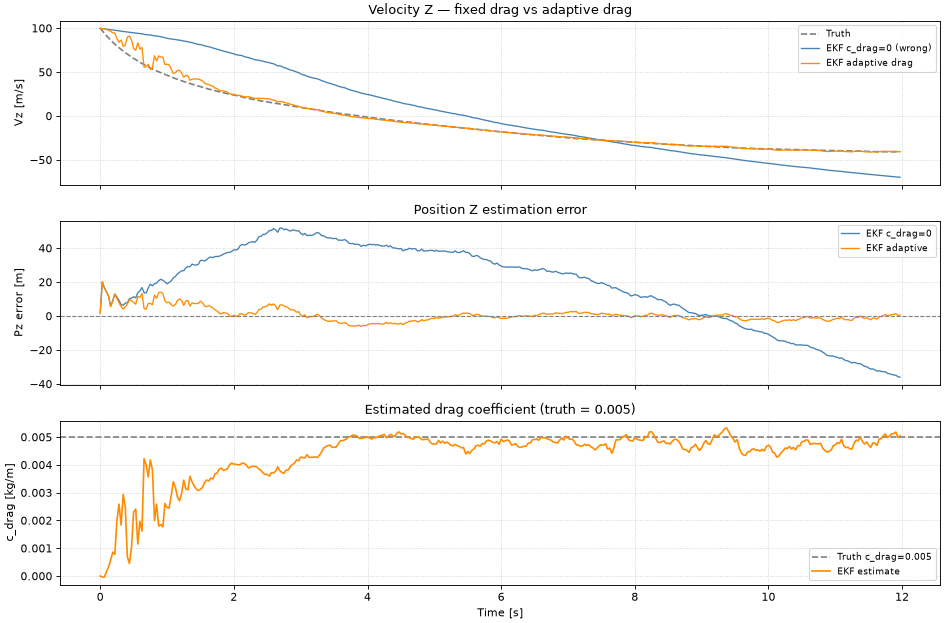

Pz RMS error — EKF fixed drag=0: 30.0 m  |  EKF adaptive: 4.2 m
Estimated c_drag at end: 0.00505  (truth: 0.005)
Chrono summary:
    #   label                             t          ΔT
  ───   ───────────────────────   ─────────   ─────────
    1.  Truth sampled              214.8 ms    214.8 ms
    2.  EKF fixed drag=0 done      439.4 ms    224.7 ms
    3.  EKF augmented drag done    707.6 ms    268.2 ms
  ───   ───────────────────────   ─────────   ─────────
        total                      844.9 ms


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.framework.filter import KalmanFilter
import kalman.runtime.chrono as chrono

# -----------------------------------------------------------------------
# BallisticAugmentedModel: 10D state [x9D, c_drag]
#
# Design notes:
# 1. f() and h() are patched as INSTANCE ATTRIBUTES after super().__init__()
#    so that _check_shapes (called during parent init) still sees the 9D model.
# 2. initial_state() is overridden to flatten the 3×3 INIT array to 9 elements
#    and then pad to 10D (c_drag=0) before passing to the parent.  The guard
#    `self.n == 10` ensures the override is a no-op during the parent __init__
#    call (when n is still 9).
# -----------------------------------------------------------------------
class BallisticAugmentedModel(BallisticModel):
    """
    Augments the 9D ballistic state with c_drag as a random-walk state (index 9).
    The filter learns c_drag from the observed deceleration pattern.
    """
    def __init__(self, name, *, drag_process_noise=1e-4, drag_initial_uncertainty=5e-3, **kwargs):
        kwargs['c_drag'] = 0.0   # placeholder; at runtime comes from state[9]
        # 1. Build the standard 9D model (passes _check_shapes intact)
        super().__init__(name, **kwargs)

        q_c     = float(drag_process_noise)
        sigma_c = float(drag_initial_uncertainty)

        # 2. Augment state dimension
        self.n = 10

        # 3. Augment Q: 9×9 → 10×10
        Q10 = np.zeros((10, 10), dtype=self.dtype)
        Q10[:9, :9] = self._Q.copy()
        Q10[9,  9]  = q_c ** 2
        self._Q = Q10

        # 4. Augment x0: c_drag starts at 0
        x0 = np.zeros((10, 1), dtype=self.dtype)
        x0[:9] = self.x0
        self.x0 = x0

        # 5. Augment P0: tight initial uncertainty for c_drag
        P0 = np.zeros((10, 10), dtype=self.dtype)
        P0[:9, :9] = self.P0
        P0[9,  9]  = sigma_c ** 2
        self.P0 = P0

        # 6. Capture parent f / h before patching (bound to self)
        _parent_f = BallisticModel.f.__get__(self, type(self))
        _parent_h = BallisticModel.h.__get__(self, type(self))
        _model    = self
        dtype     = self.dtype

        def _aug_f(x, u=None, w=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            old = _model["c_drag"]
            _model["c_drag"] = float(x[9, 0])
            x9 = _parent_f(x[:9], u=u, w=None, t=t)
            _model["c_drag"] = old
            xn = np.zeros((10, 1), dtype=dtype)
            xn[:9] = np.asarray(x9, dtype=dtype).reshape(9, 1)
            xn[9, 0] = float(x[9, 0])    # c_drag random walk: persists + noise
            if w is not None:
                xn += np.asarray(w, dtype=dtype).reshape(10, 1)
            return xn

        def _aug_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            return _parent_h(x[:9], v=v, t=t)

        self.f = _aug_f
        self.h = _aug_h

        # 7. Re-attach engine with updated dims

    def initial_state(self, x0=None, P0=None):
        """Pad a 9-element initial state to 10D (c_drag=0); no-op during parent init."""
        if x0 is not None and getattr(self, 'n', 9) == 10:
            flat = np.asarray(x0, dtype=getattr(self, 'dtype', np.float64)).ravel()
            if flat.size == 9:
                x10 = np.zeros((10, 1), dtype=flat.dtype)
                x10[:9, 0] = flat
                x0 = x10
        super().initial_state(x0=x0, P0=P0)


# -----------------------------------------------------------------------
# 1. Generate truth with c_drag = 0.005 (non-zero drag)
# -----------------------------------------------------------------------
chrono.restart()

C_DRAG_TRUE = 0.005
INIT = [[100, 100, 0], [200, 100, 0], [300, 100, -GRAVITY]]
FS, T, SEED = 32, 12, 42

truth_model = BallisticModel("XYZ", order=3, fs=FS,
                             c_drag=C_DRAG_TRUE,
                             measurement_uncertainty=30,
                             process_uncertainty=0.3,
                             random_seed=SEED)
truth_model.initial_state(INIT)
truth_sample = truth_model.sample(T)
chrono.lap("Truth sampled")

# -----------------------------------------------------------------------
# 2. Filter A: wrong fixed drag (c_drag = 0)
# -----------------------------------------------------------------------
ekf_nodrag = BallisticModel("XYZ", order=3, fs=FS,
                            c_drag=0.0,
                            measurement_uncertainty=30,
                            process_uncertainty=0.3)
ekf_nodrag.initial_state(INIT)
rec_nodrag = ekf_nodrag.filter(truth_sample.zk, smooth=False, reset=True)
chrono.lap("EKF fixed drag=0 done")

# -----------------------------------------------------------------------
# 3. Filter B: augmented model (adaptive c_drag)
# -----------------------------------------------------------------------
ekf_aug = BallisticAugmentedModel("XYZ", order=3, fs=FS,
                                  measurement_uncertainty=30,
                                  process_uncertainty=0.3,
                                  drag_process_noise=1e-4,
                                  drag_initial_uncertainty=5e-3)
ekf_aug.initial_state(INIT)
rec_aug = ekf_aug.filter(truth_sample.zk, smooth=False, reset=True)
chrono.lap("EKF augmented drag done")

# -----------------------------------------------------------------------
# Plot: velocity Z and estimated c_drag
# -----------------------------------------------------------------------
t = truth_sample.time

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].set_title("Velocity Z — fixed drag vs adaptive drag")
axes[0].plot(t, truth_sample.xk[:, 7], '--', color='gray',       lw=1.5, label='Truth')
axes[0].plot(t, rec_nodrag.xk[:, 7],   '-',  color='steelblue',  lw=1.2, label='EKF c_drag=0 (wrong)')
axes[0].plot(t, rec_aug.xk[:, 7],       '-',  color='darkorange', lw=1.2, label='EKF adaptive drag')
axes[0].set_ylabel("Vz [m/s]"); axes[0].legend(fontsize=8); axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title("Position Z estimation error")
axes[1].plot(t, rec_nodrag.xk[:, 6] - truth_sample.xk[:, 6], '-', color='steelblue',  lw=1.2, label='EKF c_drag=0')
axes[1].plot(t, rec_aug.xk[:, 6]    - truth_sample.xk[:, 6], '-', color='darkorange',  lw=1.2, label='EKF adaptive')
axes[1].axhline(0, color='gray', lw=1, linestyle='--')
axes[1].set_ylabel("Pz error [m]"); axes[1].legend(fontsize=8); axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].set_title(f"Estimated drag coefficient (truth = {C_DRAG_TRUE})")
axes[2].axhline(C_DRAG_TRUE, color='gray', lw=1.5, linestyle='--', label=f'Truth c_drag={C_DRAG_TRUE}')
axes[2].plot(t, rec_aug.xk[:, 9], '-', color='darkorange', lw=1.5, label='EKF estimate')
axes[2].set_ylabel("c_drag [kg/m]"); axes[2].set_xlabel("Time [s]")
axes[2].legend(fontsize=8); axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

rms_nd = np.sqrt(np.mean((rec_nodrag.xk[:, 6] - truth_sample.xk[:, 6])**2))
rms_ag = np.sqrt(np.mean((rec_aug.xk[:, 6]    - truth_sample.xk[:, 6])**2))
print(f"Pz RMS error — EKF fixed drag=0: {rms_nd:.1f} m  |  EKF adaptive: {rms_ag:.1f} m")
print(f"Estimated c_drag at end: {rec_aug.xk[-1, 9]:.5f}  (truth: {C_DRAG_TRUE})")
chrono.summary()

## Step 8 — UKF vs. EKF Comparison

Both filters handle nonlinearity, but in different ways. Knowing *when each one wins* is a core practical skill.

**Key terms**
- **EKF** — linearises with the first-order **Jacobian**, $F=\partial f/\partial\mathbf x$. It is exact for linear systems. Its error grows with the *curvature* of $f$.
- **Unscented transform (UT)** — instead of differentiating, push a small, deterministically chosen set of **sigma points** through the *exact* nonlinear function. Then recompute their mean and covariance.
- **UKF** — applies the UT. It captures effects up to **second order**, with **no Jacobian** needed. You supply only $f$ and $h$.

| | EKF | UKF |
|---|---|---|
| Linearisation | first-order Jacobian | sigma-point UT (2nd order) |
| Needs | a Jacobian (analytic or numeric) | only $f$, $h$ |
| Cost per step | $\mathcal O(n^2)$ | $\mathcal O(n^3)$ (Cholesky) |
| Best when | mild nonlinearity | stronger nonlinearity |

For the near-linear ballistic model, the two filters give comparable results. With stronger nonlinearity (steep elevation, heavy drag) the UKF usually gives a tighter, more consistent covariance.

**Usage.** `UnscentedKalmanFilter(model)` wraps the *same* `BallisticModel`. Only the **engine** (the estimation algorithm) changes, not the model. It returns a `KalmanRecord`, like every other filter.


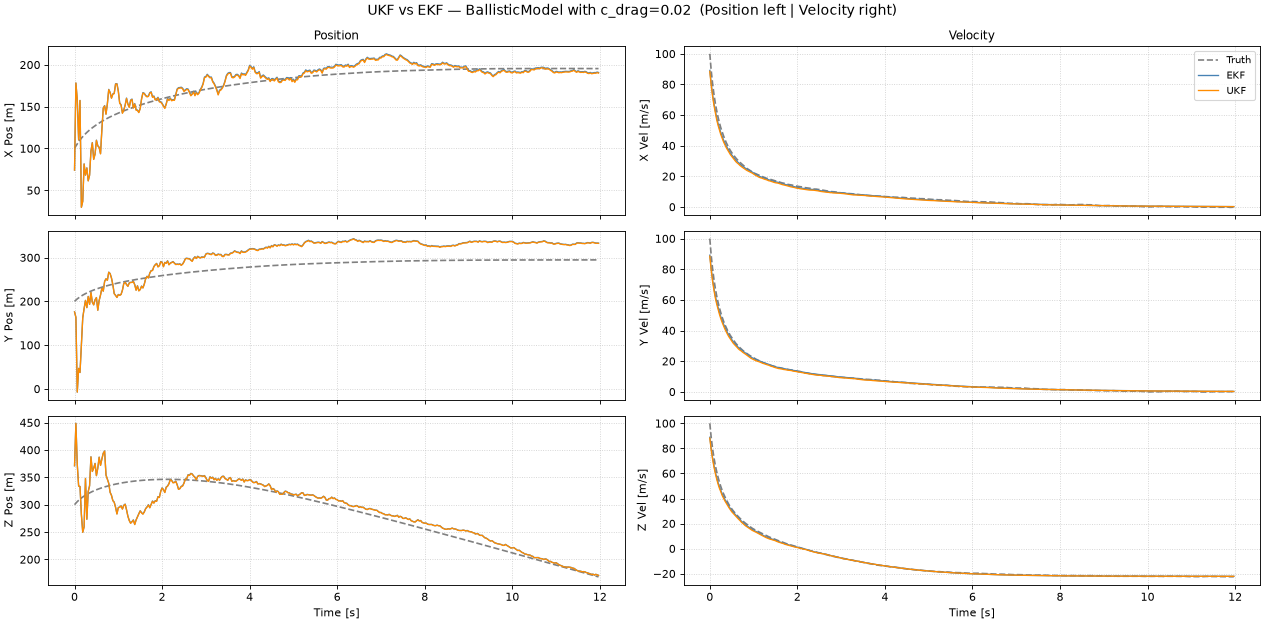

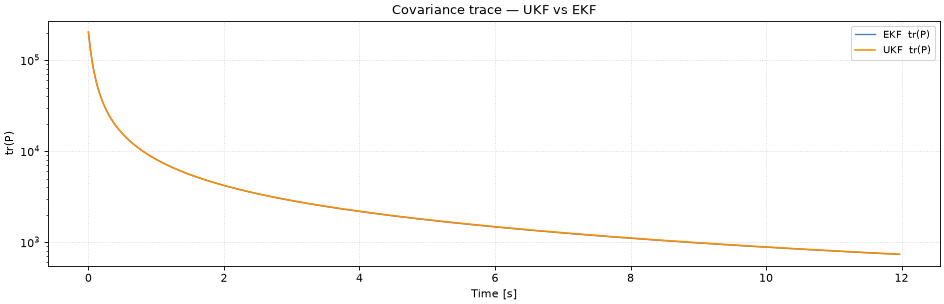

Component               EKF RMS      UKF RMS
--------------------------------------------
Position X                14.06 m     13.82 m
Position Y                41.93 m     41.29 m
Position Z                22.87 m     22.89 m
Velocity X                 1.11 m/s      1.40 m/s
Velocity Y                 1.01 m/s      1.24 m/s
Velocity Z                 1.10 m/s      1.35 m/s
Chrono summary:
    #   label                   t          ΔT
  ───   ─────────────   ─────────   ─────────
    1.  Truth sampled    206.6 ms    206.6 ms
    2.  EKF done         433.1 ms    226.5 ms
    3.  UKF done         859.4 ms    426.3 ms
  ───   ─────────────   ─────────   ─────────
        total             1.117 s


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.filters.ukf import UnscentedKalmanFilter
import kalman.runtime.chrono as chrono

chrono.restart()

# -----------------------------------------------------------------------
# Use non-zero drag to expose nonlinearity (UKF advantage over EKF)
# -----------------------------------------------------------------------
C_DRAG_CMP = 0.02     # stronger drag → more nonlinearity
INIT_CMP   = [[100, 100, 0], [200, 100, 0], [300, 100, -GRAVITY]]
FS_CMP, T_CMP, SEED_CMP = 32, 12, 99

truth_cmp = BallisticModel("XYZ", order=3, fs=FS_CMP,
                            c_drag=C_DRAG_CMP,
                            measurement_uncertainty=300,
                            process_uncertainty=0.3,
                            random_seed=SEED_CMP)
truth_cmp.initial_state(INIT_CMP)
sample_cmp = truth_cmp.sample(T_CMP)
chrono.lap("Truth sampled")

# -----------------------------------------------------------------------
# EKF  — standard framework filter (linearises via Jacobian)
# -----------------------------------------------------------------------
ekf_cmp = BallisticModel("XYZ", order=3, fs=FS_CMP,
                          c_drag=C_DRAG_CMP,
                          measurement_uncertainty=300,
                          process_uncertainty=0.3)
ekf_cmp.initial_state(INIT_CMP)
rec_ekf = ekf_cmp.filter(sample_cmp.zk, smooth=False, reset=True)
chrono.lap("EKF done")

# -----------------------------------------------------------------------
# UKF  — UnscentedKalmanFilter from kalman.filters.ukf
#         returns (xk, Pk) raw arrays (N, n) and (N, n, n)
# -----------------------------------------------------------------------
ukf_model = BallisticModel("XYZ", order=3, fs=FS_CMP,
                            c_drag=C_DRAG_CMP,
                            measurement_uncertainty=300,
                            process_uncertainty=0.3)
ukf_model.initial_state(INIT_CMP)

ukf = UnscentedKalmanFilter(ukf_model, alpha=1e-3, beta=2.0, kappa=0.0)
rec_ukf = ukf.filter(sample_cmp.zk, reset=True)
xk_ukf, Pk_ukf = rec_ukf.xk, rec_ukf.Pk
chrono.lap("UKF done")

# -----------------------------------------------------------------------
# Column-wise plot: rows = X / Y / Z, cols = Position | Velocity
# -----------------------------------------------------------------------
t_cmp       = sample_cmp.time
axes_labels = ["X", "Y", "Z"]
idx_pos     = [0, 3, 6]
idx_vel     = [1, 4, 7]

fig, axes = plt.subplots(3, 2, figsize=(16, 8), sharex=True)
fig.suptitle(
    f"UKF vs EKF — BallisticModel with c_drag={C_DRAG_CMP}  "
    f"(Position left | Velocity right)",
    fontsize=13)

for row, (lbl, pos_dim, vel_dim) in enumerate(zip(axes_labels, idx_pos, idx_vel)):
    for col, (dim, unit, comp) in enumerate([(pos_dim, "m", "Pos"), (vel_dim, "m/s", "Vel")]):
        ax = axes[row, col]
        truth = sample_cmp.xk[:, dim]
        ax.plot(t_cmp, truth,                '--', color='gray',       lw=1.5, label='Truth')
        ax.plot(t_cmp, rec_ekf.xk[:, dim],  '-',  color='steelblue',  lw=1.2, label='EKF')
        ax.plot(t_cmp, xk_ukf[:, dim],      '-',  color='darkorange', lw=1.2, label='UKF')
        ax.set_ylabel(f"{lbl} {comp} [{unit}]")
        ax.grid(True, linestyle=':', alpha=0.6)
        if row == 0:
            ax.set_title(f"{'Position' if col == 0 else 'Velocity'}", fontsize=11)
        if row == 0 and col == 1:
            ax.legend(loc='upper right', fontsize=9)

axes[-1, 0].set_xlabel("Time [s]")
axes[-1, 1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------
# Covariance trace: UKF vs EKF
# -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.semilogy(t_cmp, np.trace(rec_ekf.Pk, axis1=1, axis2=2),
            '-', color='steelblue',  lw=1.2, label='EKF  tr(P)')
ax.semilogy(t_cmp, np.trace(Pk_ukf,    axis1=1, axis2=2),
            '-', color='darkorange', lw=1.4, label='UKF  tr(P)')
ax.set_xlabel("Time [s]"); ax.set_ylabel("tr(P)")
ax.set_title("Covariance trace — UKF vs EKF")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

# -----------------------------------------------------------------------
# RMS error summary
# -----------------------------------------------------------------------
print(f"{'Component':<18} {'EKF RMS':>12} {'UKF RMS':>12}")
print("-" * 44)
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth  = sample_cmp.xk[:, dim]
        rms_e  = np.sqrt(np.mean((rec_ekf.xk[:, dim] - truth) ** 2))
        rms_u  = np.sqrt(np.mean((xk_ukf[:, dim]     - truth) ** 2))
        print(f"{name} {axes_labels[i]:<12}  {rms_e:>8.2f} {unit}  {rms_u:>8.2f} {unit}")

chrono.summary()


## Step 9 — Multi-Rate Sensor Fusion (GPS at 10 Hz in a 128 Hz Loop)

### Motivation

Different sensors run at different rates. A GPS fix arrives at **10 Hz**, but the projectile's state changes on a **millisecond** scale.

Filtering only at 10 Hz leaves 100 ms gaps with no state propagation. Drift accumulates in these gaps, and fast events between fixes stay invisible.

**Key terms**
- **Multi-rate fusion** — predict at the *fast* base rate, and update whenever *any* sensor delivers data.
- **Prediction-only step** — between measurements, the filter runs only the predict stage. It advances the state and **grows** the covariance, honestly reflecting the rising uncertainty.
- **NaN masking** — the framework's convention for "no measurement this step." A `NaN` row in `zk` triggers a predict-only step; the engine skips the update for the missing channels.

Run the loop at **128 Hz** and inject GPS data only when it arrives:
```
t = 0   ms   GPS fires  → predict + update   ([px, py, pz])
t = 7.8 ms   GPS silent → predict only       ([nan, nan, nan])
t = 100 ms   GPS fires  → predict + update
```
`make_multirate_input([(z_gps, 10.0)], base_fs=128)` builds this NaN-padded matrix automatically.

| Filter | Rate | Notes |
|---|---|---|
| 128 Hz "oracle" | 128 Hz | **Not a real sensor.** A separate run of the *same* filter, pretending a position fix arrives on every single 128 Hz tick (all 1024 of them, versus the 80 GPS fixes we actually get). It is an unreachable upper bound, useful only as a yardstick. |
| 10 Hz naive | 10 Hz | A *separate* filter instance (`model_10`), running entirely at 10 Hz. It is fed only the 80 real GPS fixes, with no fast prediction at all. |
| Multi-rate | 128 Hz predict / 10 Hz update | The proposed middle ground. It uses the same fast filter as the oracle, but only 80 of its 1024 ticks get a real correction. The rest are NaN, so they are predict-only. |

*What to look for:* the multi-rate filter tracks **position** almost as well as the 128 Hz oracle between GPS pulses. Fast prediction integrates the already-known dynamics well in that gap. The 10-Hz-only filter, by contrast, visibly steps and drifts in the gaps. **Velocity behaves differently** — see the note after the plots below.


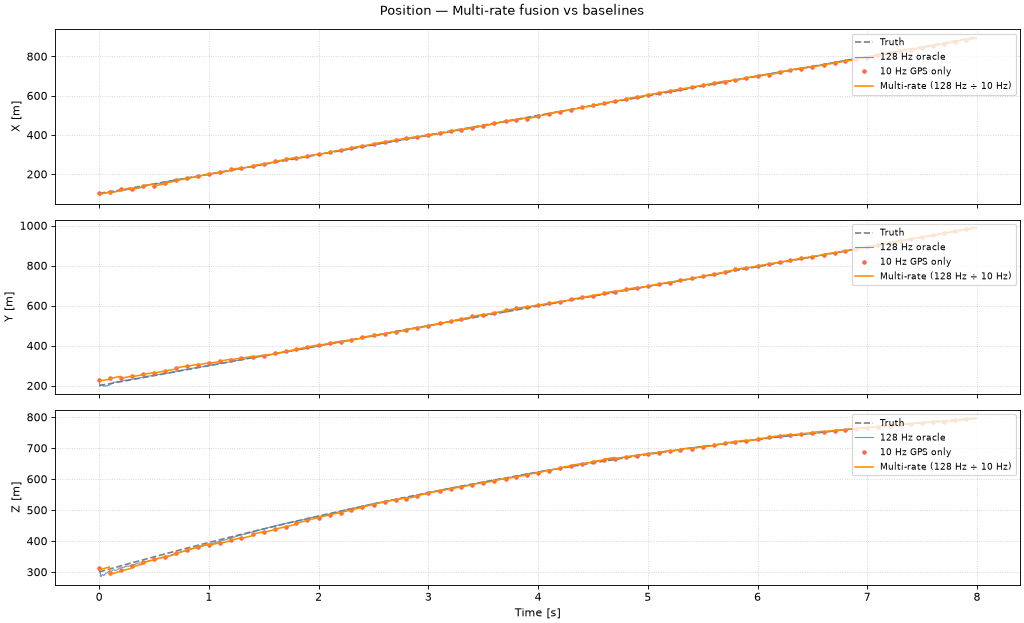

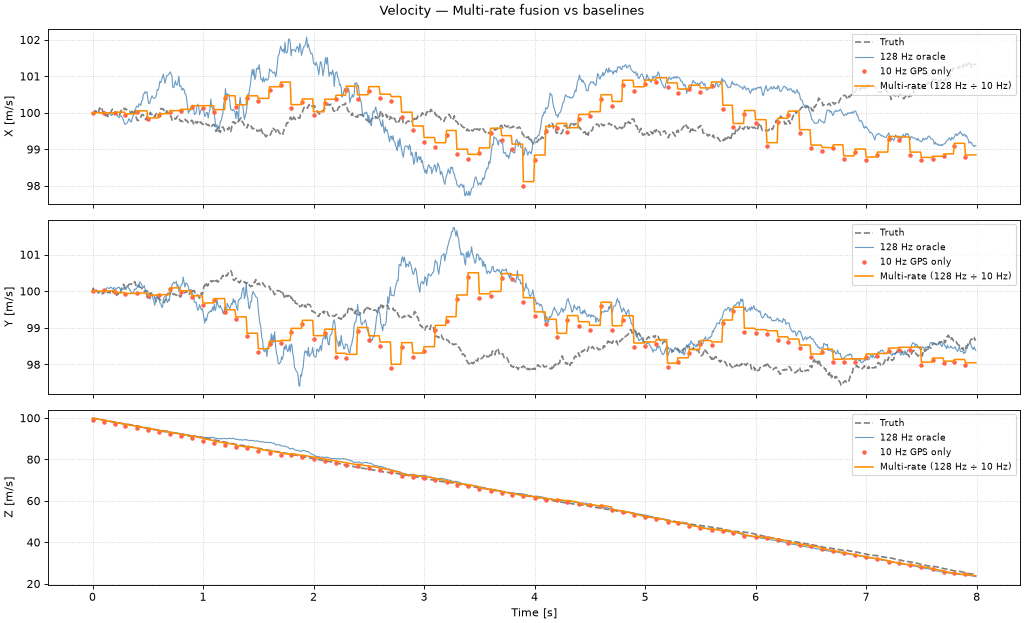

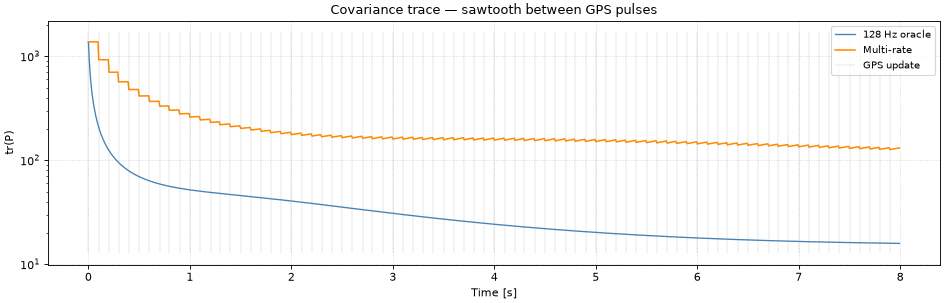

Position X:  128 Hz=   2.74 m  |  GPS only=   3.38 m  |  Multi-rate=   3.44 m
Position Y:  128 Hz=   2.01 m  |  GPS only=   7.48 m  |  Multi-rate=   7.11 m
Position Z:  128 Hz=   3.34 m  |  GPS only=   5.18 m  |  Multi-rate=   5.56 m
Velocity X:  128 Hz=   1.14 m/s  |  GPS only=   0.99 m/s  |  Multi-rate=   0.98 m/s
Velocity Y:  128 Hz=   1.18 m/s  |  GPS only=   0.91 m/s  |  Multi-rate=   0.94 m/s
Velocity Z:  128 Hz=   1.47 m/s  |  GPS only=   0.94 m/s  |  Multi-rate=   0.78 m/s
Chrono summary:
    #   label                          t          ΔT
  ───   ────────────────────   ─────────   ─────────
    1.  Sampling done           558.6 ms    558.6 ms
    2.  128 Hz baseline done     1.181 s    622.3 ms
    3.  10 Hz naive GPS done     1.229 s     48.6 ms
    4.  Multi-rate done          1.788 s    558.1 ms
  ───   ────────────────────   ─────────   ─────────
        total                    2.094 s


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.helpers import make_multirate_input
import kalman.runtime.chrono as chrono

chrono.restart()

# -----------------------------------------------------------------------
# Configuration
# -----------------------------------------------------------------------
FS_BASE   = 128.0   # base (prediction) rate [Hz]
FS_GPS    = 10.0    # GPS update rate [Hz]
T         = 8.0     # simulation duration [s]
SEED      = 17
INIT      = [[100, 100, 0], [200, 100, 0], [300, 100, -GRAVITY]]

# -----------------------------------------------------------------------
# Model at base rate
# -----------------------------------------------------------------------
model = BallisticModel("XYZ", order=3, fs=FS_BASE,
                       measurement_uncertainty=30,
                       process_uncertainty=0.5,
                       random_seed=SEED)
model.initial_state(INIT)

# -----------------------------------------------------------------------
# Truth + full-rate measurements (oracle baseline)
# -----------------------------------------------------------------------
sample = model.sample(T)
N_base = len(sample.zk)                           # = T * FS_BASE = 1024
chrono.lap("Sampling done")

# -----------------------------------------------------------------------
# A: 128 Hz filter — oracle baseline (all measurements available)
# -----------------------------------------------------------------------
rec_full = model.filter(sample.zk, smooth=False, reset=True)
chrono.lap("128 Hz baseline done")

# -----------------------------------------------------------------------
# B: GPS-only at 10 Hz — naive: subsample measurements, filter at 10 Hz
# Use exactly int(T*FS_GPS) GPS samples so make_multirate_input outputs
# exactly N_base rows when passed to the multi-rate filter.
# -----------------------------------------------------------------------
model_10 = BallisticModel("XYZ", order=3, fs=FS_GPS,
                          measurement_uncertainty=30,
                          process_uncertainty=0.5)
model_10.initial_state(INIT)

# GPS fires at times 0, 1/FS_GPS, 2/FS_GPS, ... → map to nearest base index
n_gps     = int(T * FS_GPS)                       # = 80
gps_idx   = np.clip(
    np.round(np.arange(n_gps) * FS_BASE / FS_GPS).astype(int),
    0, N_base - 1
)
z_gps_only = sample.zk[gps_idx]                   # (80, 3) — exactly T*FS_GPS rows
t_gps      = sample.time[gps_idx]
rec_gps    = model_10.filter(z_gps_only, smooth=False, reset=True)
chrono.lap("10 Hz naive GPS done")

# -----------------------------------------------------------------------
# C: Multi-rate — 128 Hz predict, 10 Hz update
# make_multirate_input: duration = 80/10 = 8.0 s → N_base = 1024 rows ✓
# -----------------------------------------------------------------------
z_multirate = make_multirate_input([(z_gps_only, FS_GPS)], base_fs=FS_BASE)
assert len(z_multirate) == N_base, f"Expected {N_base} rows, got {len(z_multirate)}"
rec_mr = model.filter(z_multirate, smooth=False, reset=True)
chrono.lap("Multi-rate done")

# -----------------------------------------------------------------------
# Plot: position and velocity across all three filters
# -----------------------------------------------------------------------
t_full     = sample.time
axes_labels = ["X", "Y", "Z"]
idx_pos     = [0, 3, 6]
idx_vel     = [1, 4, 7]

for component, indices, unit in [("Position", idx_pos, "m"),
                                  ("Velocity", idx_vel, "m/s")]:
    fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    fig.suptitle(f"{component} — Multi-rate fusion vs baselines", fontsize=12)
    for ax, dim, lbl in zip(axes, indices, axes_labels):
        truth = sample.xk[:, dim]
        ax.plot(t_full, truth,                   '--', color='gray',       lw=1.5, label='Truth')
        ax.plot(t_full, rec_full.xk[:, dim],     '-',  color='steelblue',  lw=1.0, alpha=0.8, label='128 Hz oracle')
        ax.plot(t_gps,  rec_gps.xk[:, dim],      'o',  color='tomato',     ms=3,   label=f'{FS_GPS:.0f} Hz GPS only')
        ax.plot(t_full, rec_mr.xk[:, dim],       '-',  color='darkorange', lw=1.4, label='Multi-rate (128 Hz ÷ 10 Hz)')
        ax.set_ylabel(f"{lbl} [{unit}]")
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.6)
    axes[-1].set_xlabel("Time [s]")
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------
# Covariance trace over time: multi-rate vs oracle
# -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
trace_full = np.trace(rec_full.Pk, axis1=1, axis2=2)
trace_mr   = np.trace(rec_mr.Pk,   axis1=1, axis2=2)
ax.semilogy(t_full, trace_full, '-', color='steelblue',  lw=1.2, label='128 Hz oracle')
ax.semilogy(t_full, trace_mr,   '-', color='darkorange', lw=1.4, label='Multi-rate')
# Mark GPS fire times
gps_times = t_full[~np.isnan(z_multirate[:, 0])]
ylim = ax.get_ylim()
ax.vlines(gps_times, ylim[0], ylim[1], color='gray', lw=0.4, alpha=0.4, label='GPS update')
ax.set_xlabel("Time [s]"); ax.set_ylabel("tr(P)")
ax.set_title("Covariance trace — sawtooth between GPS pulses")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

# -----------------------------------------------------------------------
# RMS error summary
# -----------------------------------------------------------------------
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth  = sample.xk[:, dim]
        rms_f  = np.sqrt(np.mean((rec_full.xk[:, dim] - truth)**2))
        rms_mr = np.sqrt(np.mean((rec_mr.xk[:, dim]   - truth)**2))
        # Interpolate 10 Hz GPS record to full-rate grid for fair comparison
        xk_gps_interp = np.interp(t_full, t_gps, rec_gps.xk[:, dim])
        rms_g  = np.sqrt(np.mean((xk_gps_interp - truth)**2))
        print(f"{name} {axes_labels[i]}:  "
              f"128 Hz={rms_f:7.2f} {unit}  |  "
              f"GPS only={rms_g:7.2f} {unit}  |  "
              f"Multi-rate={rms_mr:7.2f} {unit}")

chrono.summary()

### Interpreting the Plots: Why Velocity Does Not Show "Best of Both"

Position and velocity behave differently here, because only **position is measured**. (`BallisticModel.h` returns `[px, py, pz]`; velocity is a hidden state.)

The filter can only learn about velocity indirectly. It does this through the Kalman gain, acting on a position residual, at an update step.

- **Position** — multi-rate tracking stays close to the 128 Hz oracle. Between GPS fixes, the fast predict step just integrates an already well-known velocity estimate through known dynamics. No new information is needed to do that well.
- **Velocity** — the oracle gets a correction opportunity 128 times per second. Multi-rate gets only 10 corrections per second, 12.8 times fewer. Between fixes, the multi-rate velocity estimate runs freely on the process model alone. Its error can grow for up to 100 ms before the next correction arrives. This causes the drift and stair-stepping you see in the velocity panels, and why it visibly lags the oracle there.

This is not a defect. It is the fundamental limit of correcting an *unobserved* state at a slower rate. Multi-rate fusion is genuinely "best of both worlds" for position. For velocity, it is a real improvement over the naive 10 Hz filter, but it cannot close the gap to the 128 Hz oracle the way position does.
